# Nereus tutorial: radial velocities, transits and Gaia astrometry

Five fits, each adding a kind of data, on published systems and public data only:

| § | fit | system | data |
|---|---|---|---|
| 1 | RV alone | NGTS-6 b | 11 CORALIE and 10 FEROS velocities (Vines et al. 2019) |
| 2 | RV + transits | NGTS-6 b | the same velocities and five sectors of TESS 2-min photometry |
| 3 | astrometry alone | Gaia-4 b | Gaia DR4 pre-release epoch astrometry |
| 4a | RV + astrometry | Gaia-4 b | HPF, NEID and FIES velocities with Gaia DR4 |
| 4b | RV + astrometry | HD 114762 b | 29 years of Keck and Lick velocities with Gaia DR4 |

Each step measures something the previous one cannot. Radial velocities give the
period, the eccentricity and $M \sin i$. A transit adds the radius and the inclination,
for the few orbits that happen to be aligned. Astrometry measures the orbit on the sky,
and with it the inclination and the true mass, whatever the alignment.

The notebook drives Nereus from Python through `astronereus`. The Julia package fits
the same models with the same code underneath (§0.2). Run top to bottom it takes about
15 minutes with 16 threads, most of it in §2–4, plus the downloads on a
first run.

## 0. Install

### 0.1 Python

```sh
pip install "astronereus[diagnostics,lightcurves]"
python -c "import astronereus; astronereus.install()"
```

The first line installs the Python package; `diagnostics` adds the readers for the
chain files (§3) and `lightcurves` adds `lightkurve`, which downloads the TESS data in
§2. The second line fetches the prebuilt Nereus runtime (Julia and every dependency,
about 480 MB on Apple silicon and 650–700 MB on Linux), unpacks it into a cache and
compiles it once. You do not need Julia installed. If you skip it, the first fit does the
same automatically; do it ahead of time before a workshop or a flight. `NEREUS_HOME`
chooses the cache directory.

The package is `astronereus` on PyPI because `nereus` there is an unrelated geophysics
package. Everywhere else the name is Nereus.

The Gaia DR4 pre-release epoch astrometry (§3–4) is downloaded on first use and
cached in `~/.nereus` (`NEREUS_DATA_CACHE` moves it). It comes as a 0.6 MB zip that
Nereus unpacks with the system `unzip` command: macOS ships it, minimal Linux images
may not (`apt install unzip`).

### 0.2 Julia

```julia
using Pkg; Pkg.add(url="https://github.com/jvines/Nereus.jl")
```

In Julia a fit is `build_target(...)` followed by a sampler call such as
`sample_pt_emcee(target, target.data; n_temps = 16, n_walkers = 100)`. The quick start
in the [Nereus.jl README](https://github.com/jvines/Nereus.jl) is §4a of this notebook
in Julia, and the notebooks `01` and `02` in its
[examples](https://github.com/jvines/Nereus.jl/tree/main/examples) are §3 and §4b.

In [1]:
import os
from collections import Counter

import numpy as np
import xarray as xr
from IPython.display import display

import astronereus
from astronereus import RV, Transit, Astrometry, engines

print("astronereus", astronereus.__version__, "runtime", astronereus.RUNTIME_VERSION)
print(astronereus.runtime_parts())      # all True once the runtime is installed

astronereus 0.4.38 runtime 0.8.10
{'julia binary': True, 'depot': True, 'julia stdlib depot': True, 'bundled project': True}


### 0.3 A session and a sampler

Fits run in a Julia process that stays up between cells, so only the first call pays
the start-up (about 20 s). Start it once and reuse it. In a notebook, do not open it
with `with`: the process would close at the end of that cell.

Every fit here uses `engines.PTEmcee`: an affine-invariant ensemble (emcee's stretch
move) run at a ladder of temperatures that swap states. The hot chains carry the cold
one between modes it would not leave on its own, which is what multimodal orbital
posteriors need. `init_strategy="prior"` starts the walkers from the prior rather than
from a guess, and `n_steps` sets the cost.

The text was checked at the default below. `NEREUS_TUTORIAL_QUICK=1` runs everything at
a fraction of the cost: enough to see each step work, not posteriors to quote.

In [2]:
QUICK = os.environ.get("NEREUS_TUTORIAL_QUICK") == "1"

def ptemcee(n_temps=16, n_walkers=100, n_steps=3000, seed=42):
    # n_steps per walker; the first half is burn-in.
    n_steps = 600 if QUICK else n_steps
    return engines.PTEmcee(n_temps=n_temps, n_walkers=n_walkers,
                           n_steps=n_steps, n_burnin=n_steps // 2,
                           init_strategy="prior", seed=seed)

def show(res, *keys):
    # Display the figures Nereus wrote whose names contain any of `keys`.
    for name, fig in res.figures.items():
        if any(k in name for k in keys):
            print(name)
            display(fig)

s = astronereus.session().start()
s.ping()

astronereus: starting the Julia daemon (up to 300s; log: /tmp/nereus-daemon-xhzjbsry/daemon.log)
astronereus: daemon ready (26s)
NEREUS_DAEMON_READY


{'julia': '1.11.9',
 'threads': 16,
 'cpu': 'generic',
 'api': 3,
 'nereus': '0.8.10',
 'pong': True}

---
## 1. Radial velocities alone: NGTS-6 b

NGTS-6 b (Vines et al. 2019, MNRAS 489, 4125) is a hot Jupiter on a 21-hour orbit
around a $V = 14$ K dwarf, found by the Next Generation Transit Survey. The paper lists
11 CORALIE and 10 FEROS velocities; they are copied below. Times are given to 0.01 d
in the paper, about 1% of this orbit.

Each instrument is its own channel with its own zero point $\gamma$ and jitter $\sigma$:
two spectrographs never share an RV offset.

In [3]:
# Vines et al. 2019, CORALIE and FEROS radial velocities:
# BJD - 2450000, RV (km/s), sigma (km/s), instrument
NGTS6_RV = '''
8415.71 -19.526 0.165 CORALIE
8418.74 -18.633 0.104 CORALIE
8454.65 -19.324 0.125 CORALIE
8472.59 -18.856 0.109 CORALIE
8472.75 -19.064 0.124 CORALIE
8475.69 -19.333 0.102 CORALIE
8475.79 -19.264 0.110 CORALIE
8481.71 -19.396 0.089 CORALIE
8481.81 -19.494 0.102 CORALIE
8492.69 -19.019 0.086 CORALIE
8492.73 -19.105 0.098 CORALIE
8481.85 -19.536 0.047 FEROS
8480.75 -19.196 0.026 FEROS
8480.73 -19.033 0.022 FEROS
8484.71 -19.189 0.016 FEROS
8478.79 -18.746 0.028 FEROS
8478.60 -19.052 0.025 FEROS
8478.81 -18.946 0.043 FEROS
8478.62 -18.874 0.026 FEROS
8483.84 -19.103 0.026 FEROS
8483.67 -19.434 0.017 FEROS
'''
rows  = [line.split() for line in NGTS6_RV.strip().splitlines()]
t_bjd = np.array([float(r[0]) for r in rows]) + 2450000.0
rv_ms = np.array([float(r[1]) for r in rows]) * 1e3      # km/s -> m/s
er_ms = np.array([float(r[2]) for r in rows]) * 1e3
inst  = [r[3] for r in rows]

# Nereus works in MJD; from_arrays sees full Julian dates and converts them.
ngts6_rv = RV.from_arrays(t_bjd, rv_ms, er_ms, instrument=inst)
Counter(inst)

Counter({'CORALIE': 11, 'FEROS': 10})

**Priors.** A parameter you do not name gets a default; here that is the two zero
points. Four choices are ours:

- The period is bracketed around the photometric one (0.882 d). RV follow-up of a
  transiting candidate always starts from the transit period; the velocities then say
  whether the signal is a planet, and how massive.
- The orbit is circular. A 21-hour orbit is tidally circularised, and the paper fixed
  $e = 0$. A bare number is a fixed parameter.
- $K$ is flat up to 1 km/s.
- The jitters are flat on [0, 300] m/s. Nereus's default jitter prior is a normal of
  $5 \pm 5$ m/s truncated to [0, 50] m/s (Vines et al. 2023), set for stabilised
  spectrographs on bright stars. CORALIE and FEROS on a $V = 14$ star scatter more than
  that, and under the default the FEROS residuals come out at four times their variance.

`M_s` is the stellar mass in solar units. It does not enter the RV model; it converts
$K$ into $M \sin i$ in the derived quantities.

In [4]:
PRIORS_RV = {
    "P_k1": {"type": "uniform", "lo": 0.85, "hi": 0.92},          # d
    "K_k1": {"type": "uniform", "lo": 0.0,  "hi": 1000.0},        # m/s
    "sesinw_k1": 0.0,                                             # circular
    "secosw_k1": 0.0,
    "sigma_CORALIE": {"type": "uniform", "lo": 0.0, "hi": 300.0}, # m/s
    "sigma_FEROS":   {"type": "uniform", "lo": 0.0, "hi": 300.0},
}

res_rv = s.fit_rv(ngts6_rv, planets=1, priors=PRIORS_RV,
                  M_s=0.767,                         # M_sun, Vines et al. 2019
                  engine=ptemcee(), plots=["rv_phasefold"],
                  output_dir="tutorial_out/ngts6_rv")
res_rv

pt_emcee | ▕████████████████████████▏ | 3000/3000 (100.0%) | acc=0.2600 | β1_acc=0.4500 | min_swap=0.2220 | Rhat=1.004/1.004 | ESS=20995/34752 | nevals=4801600 | elapsed 5s        
┌ Warning: sample_pt_emcee: bridge and mode-Laplace disagree by 22.2 nats. Reporting bridge (it is the validated one), but CHECK THE POSTERIOR IS NOT MULTIMODAL before quoting it — a single Gaussian reference cannot cover multiple modes and overlap will not tell you so.
│   bridge = -140.78301970829597
│   laplace = -162.99784773375288
│   overlap = 1.0
└ @ Nereus /work/bundle/depot/dev/Nereus/src/samplers/pt_emcee.jl:1303
plots | ▕░░░░░░░░░░░░░░░░░░░░░░░░▏ | 0/1 (0.0%) | now=rv_phasefold | elapsed 0s
┌ Warning: Could not find font Times New Roman, using TeX Gyre Heros Makie
└ @ Makie /work/bundle/depot/packages/Makie/p9K7f/src/conversions.jl:1460
post-fit | ▕███████░░░░░░░░░░░░░░░░░▏ | 2/7 (28.6%) | stage=loo | elapsed 12s             
[ Info: No source provided for samples; variables are assumed to be from

<JobResult status=ok log_z=-140.79 elapsed=38s 7 params 1 figures>

<JobResult status=ok log_z=-140.79 elapsed=38s 7 params 1 figures>

fitted parameters (7)
  K_k1               340      +32      -32  m/s
  Mo_k1            0.381   +0.086   -0.082  rad  = 21.81 deg
  P_k1           0.88250 +0.00074 -0.00075  d
  gamma_CORALIE   -19135      +39      -38  m/s
  gamma_FEROS     -19144      +26      -26  m/s
  sigma_CORALIE       56      +55      -38  m/s
  sigma_FEROS         73      +31      -20  m/s

derived quantities (6)
  P_yr_k1         0.0024162 +0.0000020 -0.0000021  yr
  a_au_k1           0.01648   +0.00053   -0.00056  AU
  ecc_k1                  0         +0         -0
  msini_earth_k1        425        +50        -49  M_earth
  msini_jup_k1         1.34      +0.16      -0.15  M_jup
  omega_deg_k1            0         +0         -0  deg
models/RV_phasefold_K1


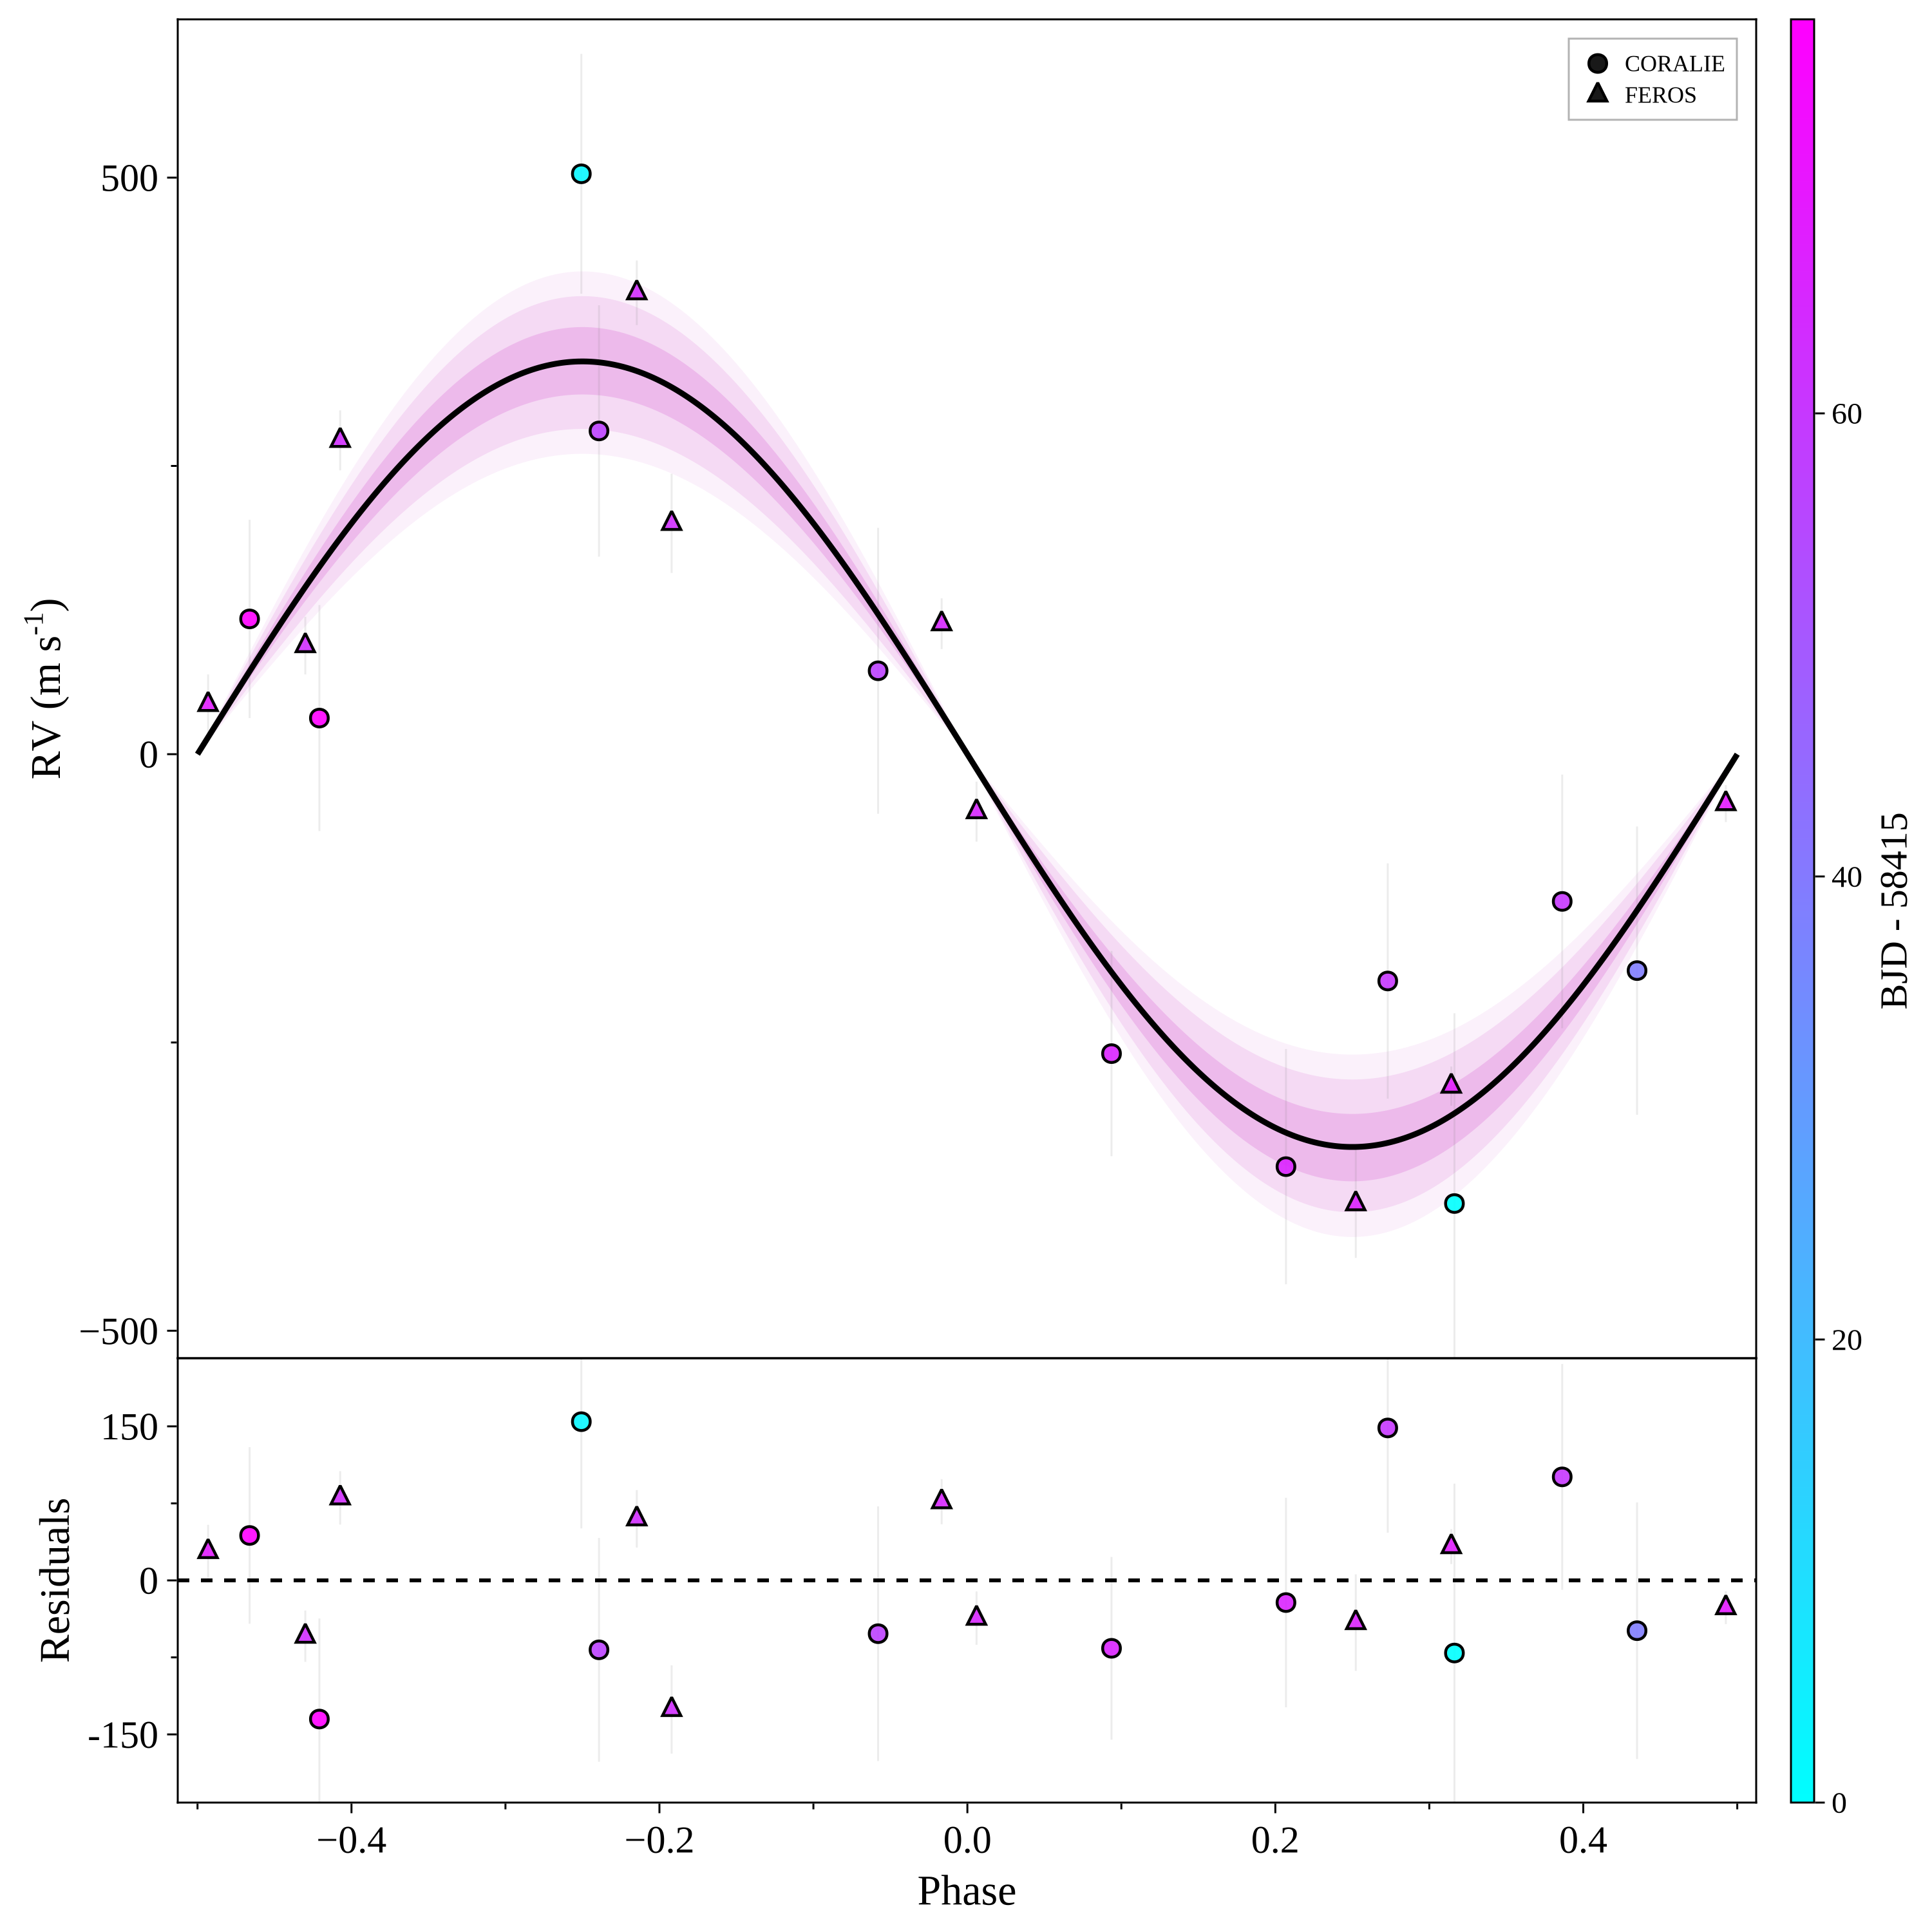

In [5]:
print(res_rv.table())
show(res_rv, "RV_phasefold")

From 21 velocities alone: $K = 340 \pm 32$ m/s and $M \sin i = 1.34 \pm 0.16\,M_J$. Vines et al., with the photometry fixing the period and phase, found $K = 322 \pm 8$ m/s and $1.339 \pm 0.028\,M_J$. The period lands at $0.88250 \pm 0.00075$ d, 0.6σ from the photometric 0.882059 d, so the velocities find the transiting signal on their own.

The jitters say where the error budget is. FEROS quotes a median 26 m/s per point and needs $73^{+31}_{-20}$ m/s on top; CORALIE's errors are four times larger, so its jitter ($56^{+55}_{-38}$ m/s) is barely constrained. The default prior stops at 50 m/s and would rule both out.

---
## 2. Radial velocities and transits: NGTS-6 b

TESS observed NGTS-6 at 2-minute cadence in sectors 5, 32, 98, 106 and 107. The SPOC
light curves (PDCSAP flux) are already corrected for light from neighbouring stars,
including the companion 5.4″ away that Vines et al. had to correct their own
photometry for, so the fit needs no dilution term.

Only the transits and a little baseline either side carry information about the planet,
so each sector is cut to ±1.9 h around every transit, using the published ephemeris.
All five sectors go in as one instrument, `TESS`: one bandpass means one limb-darkening
law, one flux offset and one jitter.

In [6]:
import lightkurve as lk

P_PHOT, TC_PHOT = 0.882059, 2457982.3784         # d, BJD_TDB (Vines et al. 2019)

for attempt in range(3):     # MAST times out now and then; a retry usually goes through
    try:
        search = lk.search_lightcurve("TIC 1528696", mission="TESS",
                                      author="SPOC", exptime=120)
        break
    except Exception as exc:
        if attempt == 2:
            raise
        print("MAST did not answer, retrying:", exc)
print(search)
lcs = search.download_all()

t, f, e = [], [], []
for lc in lcs:
    lc = lc.remove_nans().normalize()
    tb = lc.time.btjd + 2457000.0                 # TESS BTJD -> BJD_TDB
    phase = ((tb - TC_PHOT) / P_PHOT + 0.5) % 1 - 0.5
    near = np.abs(phase * P_PHOT) < 0.08          # d: +-1.9 h around each transit
    t.append(tb[near])
    f.append(lc.flux.value[near])
    e.append(lc.flux_err.value[near])
t, f, e = (np.concatenate(x) for x in (t, f, e))

print(len(t), "points; median error", round(float(np.median(e)) * 1e6), "ppm")

/usr/local/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


SearchResult containing 5 data products.

 #      mission     year author exptime target_name distance
                                   s                 arcsec 
--- --------------- ---- ------ ------- ----------- --------
  0  TESS Sector 05 2018   SPOC     120     1528696      0.0
  1  TESS Sector 32 2020   SPOC     120     1528696      0.0
  2  TESS Sector 98 2025   SPOC     120     1528696      0.0
  3 TESS Sector 106 2026   SPOC     120     1528696      0.0
  4 TESS Sector 107 2026   SPOC     120     1528696      0.0
15691 points; median error 7751 ppm


**A grazing transit.** The paper found an impact parameter $b = 0.98$: the planet
only clips the limb of its star, and the transit is V-shaped. The shape of a grazing
transit cannot separate the impact parameter, the radius ratio $R_p/R_\star$ and the
scaled orbit $a/R_\star$: a smaller planet crossing nearer the centre on a closer orbit
makes much the same dip.

The star breaks part of this. Kepler's third law turns the period and the stellar
density into $a/R_\star$, so we sample the density $\rho_\star$ (`use_rho_s`) with a
prior from the stellar mass and radius: $\rho_\star = M_\star / R_\star^3 = 0.767 /
0.754^3 = 1.79\,\rho_\odot$, with $\pm 0.11$ from their errors. Vines et al. used
the same device.

**A job config.** In this release of `astronereus`, a joint RV and transit fit goes
through `run_job`, a dict that names the data, the model and the sampler; it runs the
same fit as the `fit_*` calls. Three things differ from §1:

- priors are written as `{"type": ..., "args": [...]}`, the arguments of the Julia
  prior: `uniform` takes `[lo, hi]`; `normal` takes `[mu, sigma, lo, hi]`, and a
  density needs its lower bound;
- `planet_modes: ["RVPM"]` says the planet appears in both the velocities and the
  photometry, with one orbit: the same $P$, phase and eccentricity in both;
- the sampler is named rather than passed. `eng.name` and `eng.options()` turn the
  engine object of §0.3 into that block.

`"time": "phic"` samples the phase of the transit rather than a mean anomaly, the
natural coordinate when a transit pins it. The mid-transit time comes back as the
derived `Tc_k1`.

In [7]:
eng = ptemcee(n_temps=12, n_walkers=64)     # each step evaluates 15,000 flux points

cfg = {
    "output_dir": "tutorial_out/ngts6_rv_transit",
    "star": {"M_s": 0.767, "sigma_M_s": 0.025,      # M_sun   (Vines et al. 2019)
             "R_s": 0.754, "sigma_R_s": 0.013,      # R_sun
             "T_eff": 4730},                         # K
    "data": {
        "rv": {"values": {"bjd": t_bjd.tolist(), "rv": rv_ms.tolist(),
                          "rv_err": er_ms.tolist(), "instrument": inst}},
        "transit_photometry": [{
            "instrument": "TESS", "exposure_time": 120.0,      # s
            "values": {"bjd": t.tolist(), "flux": f.tolist(), "flux_err": e.tolist()}}],
    },
    "model": {"max_kplanet": 1, "planet_modes": ["RVPM"],
              "parametrization": {"time": "phic", "use_rho_s": True}},
    "priors": {
        "P_k1":          {"type": "uniform", "args": [0.88200, 0.88212]},      # d
        "K_k1":          {"type": "uniform", "args": [0.0, 1000.0]},           # m/s
        "rr_k1":         {"type": "uniform", "args": [0.05, 0.4]},             # Rp/R*
        "b_k1":          {"type": "uniform", "args": [0.0, 1.4]},              # grazing allowed
        "rho_s":         {"type": "normal",  "args": [1.79, 0.11, 0.1, 10.0]}, # rho_sun
        "sesinw_k1":     {"type": "fixed",   "args": [0.0]},
        "secosw_k1":     {"type": "fixed",   "args": [0.0]},
        "sigma_CORALIE": {"type": "uniform", "args": [0.0, 300.0]},            # m/s
        "sigma_FEROS":   {"type": "uniform", "args": [0.0, 300.0]},
    },
    "sampler": {"name": eng.name, "kwargs": eng.options()},
    "output": {"plots": ["rv_phasefold", "pm_phasefold", "corner"]},
}
res_rvtr = s.run_job(cfg)
res_rvtr

pt_emcee | ▕████████████████████████▏ | 3000/3000 (100.0%) | acc=0.1740 | β1_acc=0.2600 | min_swap=0.1070 | Rhat=1.013/1.017 | ESS=4355/4039 | nevals=2304768 | elapsed 54s        
[ Info: pt_emcee: burn-in moved 197 stranded walker state(s) onto their rung's mode (24 at β = 1), all from a region whose total posterior mass is bounded below e⁻¹⁰ of the mode's. The recorded chain is ordinary MCMC.
┌ Warning: sample_pt_emcee: neither bridge nor mode-Laplace is available. log_evidence is the TEMPERED value, which is biased low by 10^2-10^4 nats on a signal-locked posterior and cannot detect that it is. Do not quote it without an independent check.
│   tempered = 52582.94719688264
└ @ Nereus /work/bundle/depot/dev/Nereus/src/samplers/pt_emcee.jl:1318
post-fit | ▕███░░░░░░░░░░░░░░░░░░░░░▏ | 1/9 (11.1%) | stage=detection_limits | elapsed 2s
┌ Warning: detection_limits: chain P range covers 1.1% of the prior range — limits will only be honest inside that. EMPEROR-style prior-seeded pt_emcee is 

<JobResult status=ok log_z=52596.34 elapsed=112s 0 params 3 figures>

The period prior is narrow on purpose. Eight years of TESS data pin $P$ to about
$10^{-7}$ d, and a period off by one orbit over that baseline, $P^2/T \approx 3 \times
10^{-4}$ d, still lines up the transits within each sector. The prior keeps the sampler
on the right cycle count without excluding anything the paper allows.

A job result keeps its fitted parameters in `raw["fitted"]`; the derived quantities
print as before.

  K_k1                 341.41  +30.7 -30.3  m/s
  P_k1               0.882058  +1.41e-07 -1.35e-07  d
  b_k1                1.11461  +0.0902 -0.0772  
  gamma_CORALIE      -19135.6  +37.9 -36.9  m/s
  gamma_FEROS        -19142.5  +23.3 -24  m/s
  jitter_TESS      0.00330457  +0.000113 -0.000118  
  offset_TESS     0.000251268  +7.28e-05 -7.44e-05  
  phic_k1            -10.8249  +0.0888 -0.0923  deg
  q1_TESS            0.237286  +0.354 -0.171  
  q2_TESS            0.308529  +0.41 -0.229  
  rho_s               1.84842  +0.0959 -0.0923  rho_sun
  rr_k1               0.27112  +0.0782 -0.0656  
  sigma_CORALIE       52.1863  +52.5 -35.5  m/s
  sigma_FEROS         66.4989  +25.7 -17.6  m/s
derived quantities (26)
  P_yr_k1              0.00241494425 +0.00000000039 -0.00000000037  yr
  S_Wm2_k1                   1258354        +172862        -157096  W/m2
  S_earth_k1                     921           +126           -115  S_earth
  T14_k1                       0.891         +0.033        

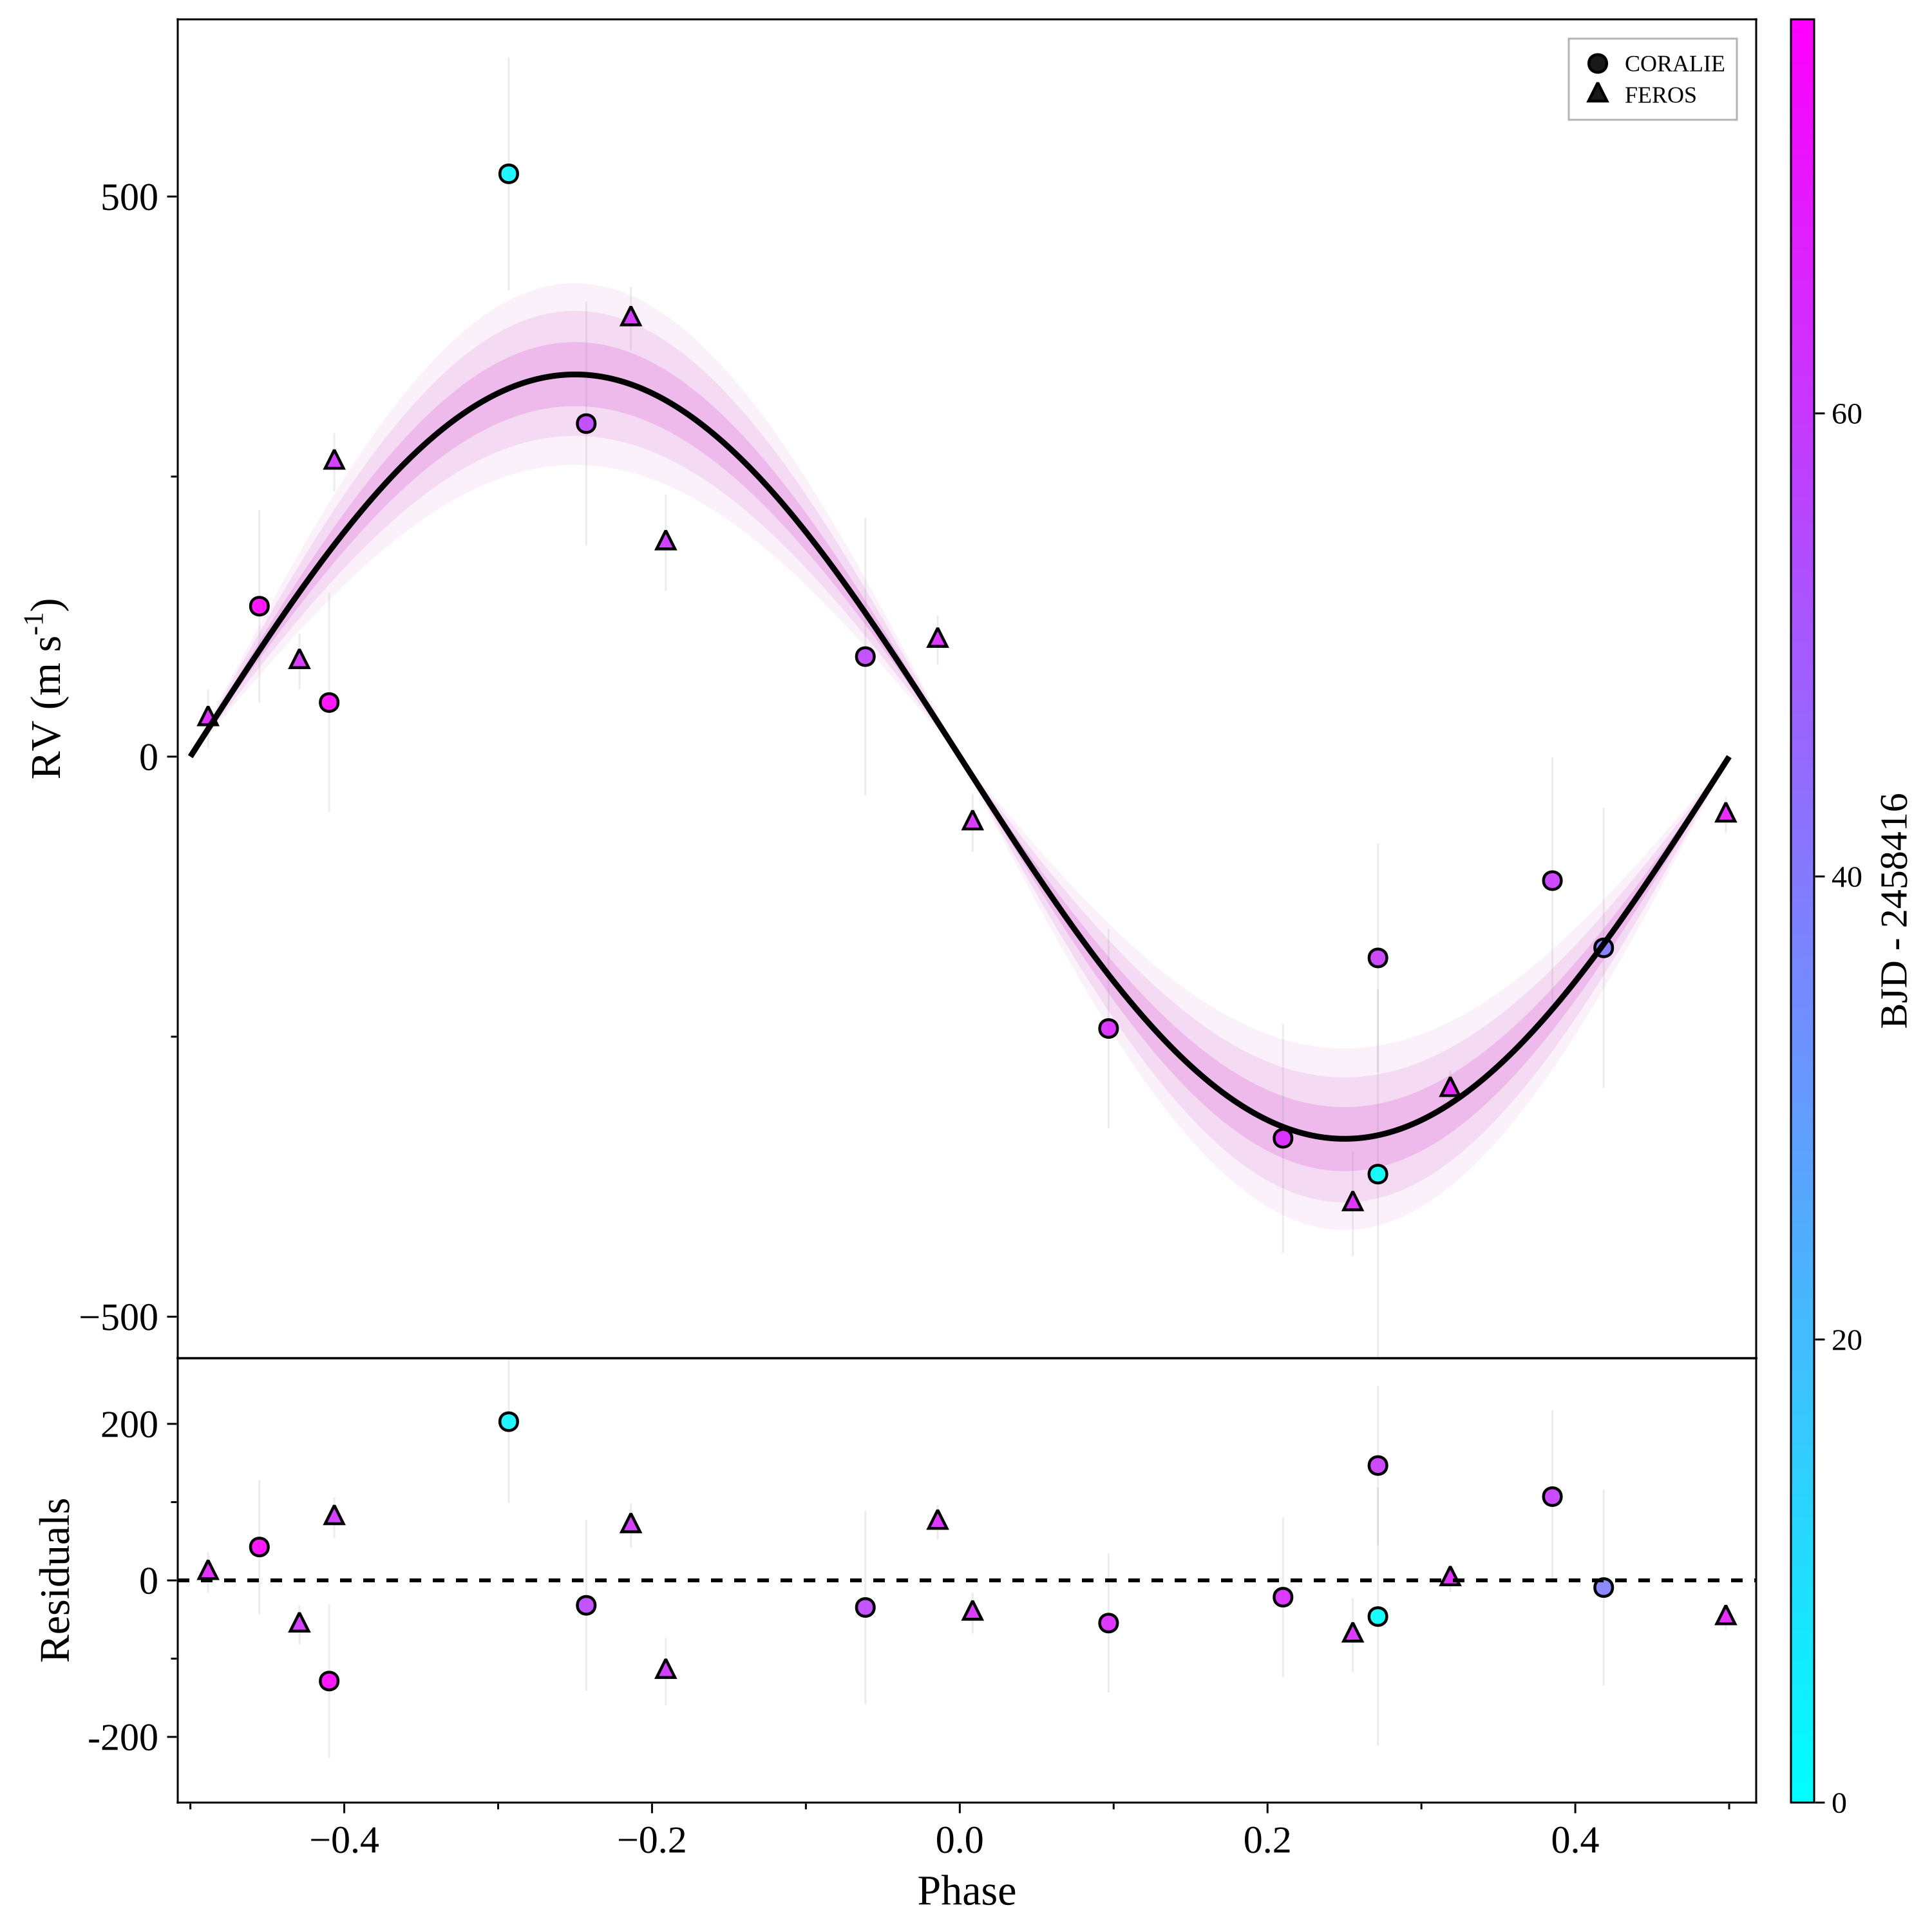

models/Transit_phasefold_K1_TESS


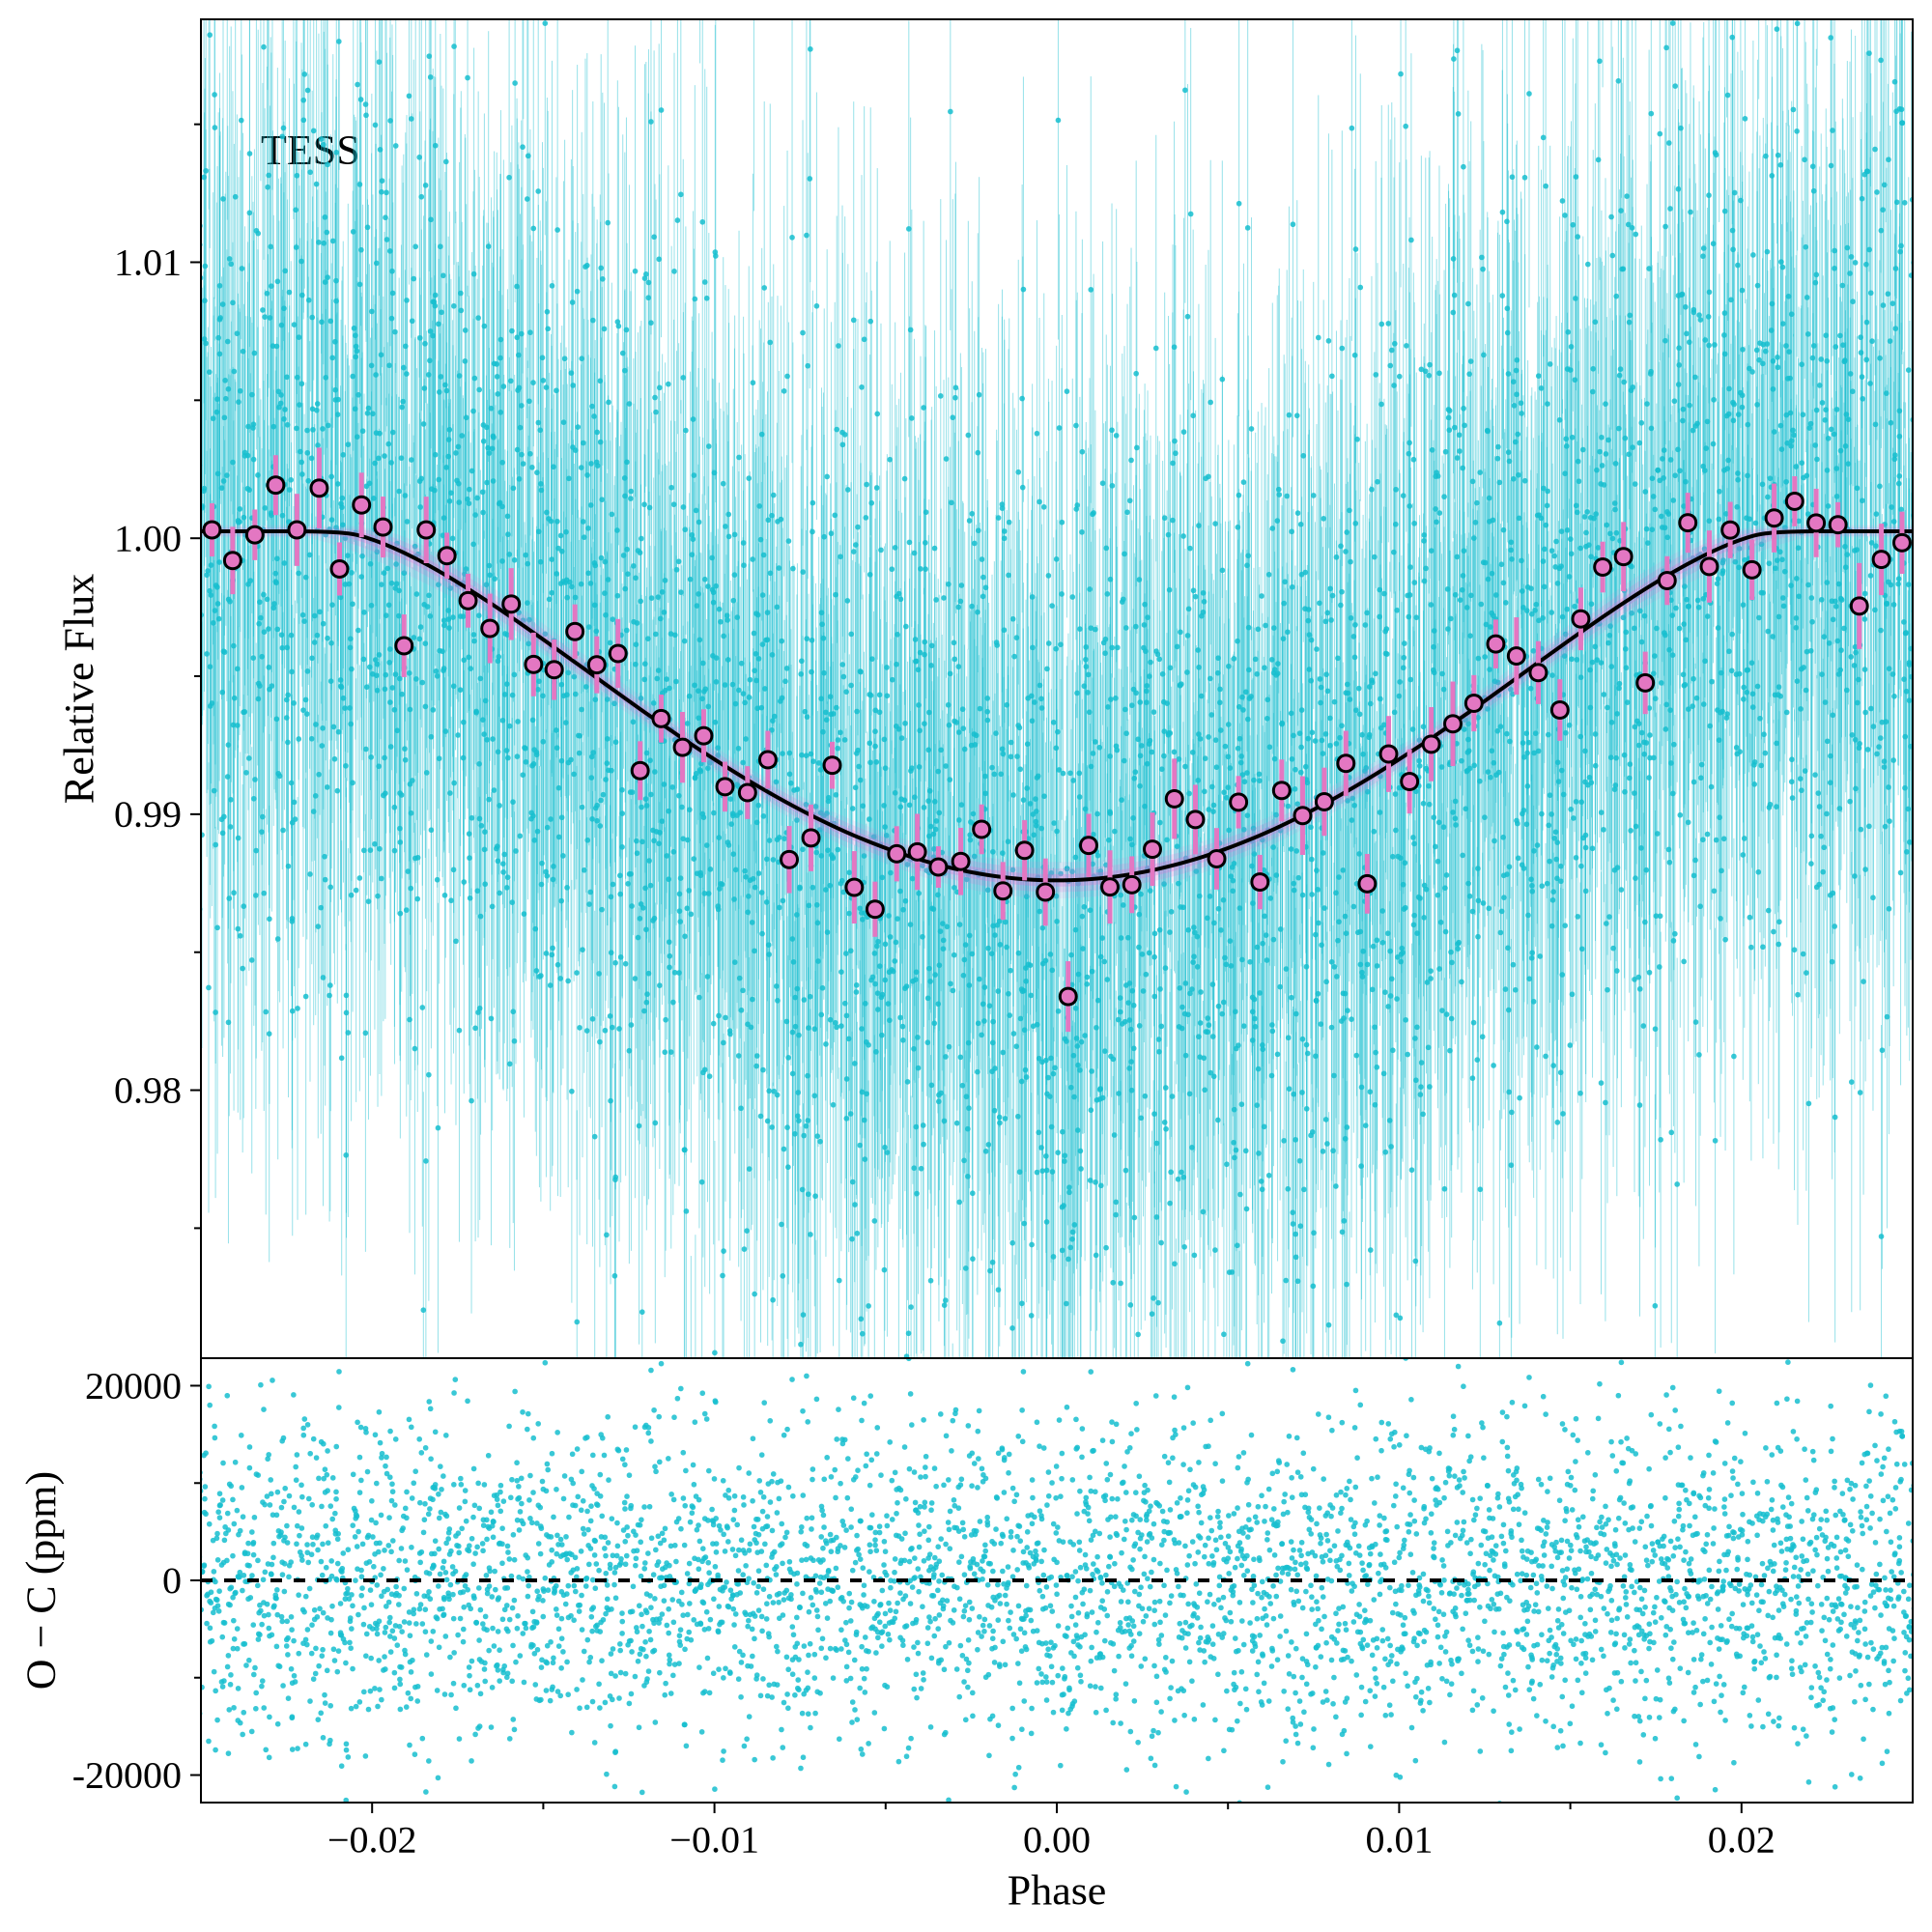

In [8]:
def print_fitted(res):
    for k, v in sorted(res.raw["fitted"]["parameters"].items()):
        print(f"  {k:14} {v['value']:12.6g}  +{v['err_hi']:.3g} -{v['err_lo']:.3g}  {v.get('unit', '')}")

print_fitted(res_rvtr)
print(res_rvtr.derived)
show(res_rvtr, "RV_phasefold", "Transit_phasefold")

The velocities return the same $K$ ($341 \pm 31$ m/s). The transit now fixes the inclination, $i = 76.4 \pm 1.1°$, so the mass is a true mass: $1.39 \pm 0.13\,M_J$. Eight years of TESS pin the period to $0.8820584 \pm 0.0000001$ d, against the paper's $0.8820590 \pm 0.0000008$ d.

The radius is where TESS alone falls short. The posterior sits in the grazing branch, $b = 1.11^{+0.09}_{-0.08}$, where $R_p/R_\star$ and $b$ trade against each other, and gives $R_p = 2.0^{+0.6}_{-0.5}\,R_J$ against the paper's $1.33\,R_J$ at $b = 0.976$. At 7,800 ppm per two-minute point on a $T = 13$ star, a V-shaped transit cannot break that degeneracy; Vines et al. had 213,549 NGTS points. The photometric residuals sit at $\chi^2/N = 1.00$: the model fits the data it was given, and those data do not pin the radius.

---
## 3. Astrometry alone: Gaia-4 b

Gaia-4 b (Stefansson et al. 2025, AJ 169, 107) is a 12 $M_J$ companion on a 571-day
orbit around a 0.64 $M_\odot$ star, found in Gaia astrometry and confirmed with RVs.

**The data.** Gaia DR4 publishes epoch astrometry: one along-scan position per CCD
crossing, with its scan angle and parallax factor. On 2026-06-26 ESA released a
pre-release sample in that format for 12 sources, Gaia-4 and HD 114762 among them;
the full DR4 follows in December 2026. Each measurement constrains the star's position
along one direction only, the scan direction of that transit.

The data are named rather than loaded: Nereus downloads the file on first use and
caches it.

**What astrometry measures.** The star moves on a small ellipse around the barycentre,
of angular size $\alpha_0 = (a\,M_{\rm sec}/M_{\rm tot})\,\varpi$. The abscissae
measure $\alpha_0$ in mas, so the companion mass follows only through the parallax
$\varpi$ and the primary mass. Both are therefore priors: an informative one for the
parallax, a fixed value for $M_{\rm pri}$. The inclination gets the isotropic prior,
$p(i) \propto \sin i$.

In [9]:
GAIA4 = {"catalogue": "gaia_dr4", "source_id": 1457486023639239296}

PRIORS_G4 = {
    "plx":      {"type": "normal",     "mu": 13.628, "sigma": 0.021},  # mas, Gaia DR3
    "M_pri":    {"type": "fixed",      "value": 0.644},                # M_sun, Stefansson et al. 2025
    "a_k1":     {"type": "loguniform", "lo": 0.3,   "hi": 4.0},        # AU
    "M_sec_k1": {"type": "loguniform", "lo": 0.001, "hi": 0.05},       # M_sun
    "inc_k1":   {"type": "sine"},
}

res_g4 = s.fit_astrometry(iad=[GAIA4], planets=1, priors=PRIORS_G4, engine=ptemcee(),
                          plots=["epoch_astrometry_orbit", "iad_residuals"],
                          output_dir="tutorial_out/gaia4_astrometry")
res_g4

pt_emcee | ▕████████████████████████▏ | 3000/3000 (100.0%) | acc=0.2050 | β1_acc=0.2100 | min_swap=0.3130 | Rhat=1.002/1.003 | ESS=42205/46745 | nevals=5282352 | elapsed 33s        
[ Info: pt_emcee: moved the seams of Mo_k1 and Omega_k1 to the emptiest arc of each posterior; windows now Mo_k1 [2.79, 9.08), Omega_k1 [1.48, 7.77). Still one full period under the same uniform prior, so this relabels the circle and changes neither the posterior nor the evidence.
[ Info: pt_emcee: node flip (Ω, ω) → (Ω + π, ω + π) on Omega_k1: 480752 proposals, acceptance 1.0 at β = 1 (1.0 over all rungs). A reversible move between the two exactly degenerate astrometric solutions; it weights them by the posterior instead of by how often swaps happened to carry walkers across.
[ Info: pt_emcee: burn-in moved 455 stranded walker state(s) onto their rung's mode (85 at β = 1), all from a region whose total posterior mass is bounded below e⁻¹⁰ of the mode's. The recorded chain is ordinary MCMC.
post-fit | ▕████

<JobResult status=ok log_z=679.26 elapsed=34s 8 params 2 figures>

<JobResult status=ok log_z=679.26 elapsed=34s 8 params 2 figures>

fitted parameters (8)
  M_sec_k1   0.01034 +0.00036 -0.00032  M_sun  = 10.8 M_jup
  Mo_k1         6.02    +0.12    -0.11  rad    = 344.74 deg
  Omega_k1      6.06    +0.14    -3.04  rad    = 347.38 deg  multimodal
  a_k1        1.1797  +0.0040  -0.0042  AU
  inc_k1       2.115   +0.040   -0.039  rad    = 121.16 deg
  plx        13.6243  +0.0061  -0.0062  mas
  secosw_k1    -0.30    +0.86    -0.25         multimodal
  sesinw_k1    -0.05    +0.43    -0.34

derived quantities (3)
  a_au_k1       1.1797 +0.0040 -0.0042  AU
  ecc_k1         0.406  +0.062  -0.060
  omega_deg_k1    -175     +32    -155  deg  multimodal
models/epoch_astrometry_orbit_K1


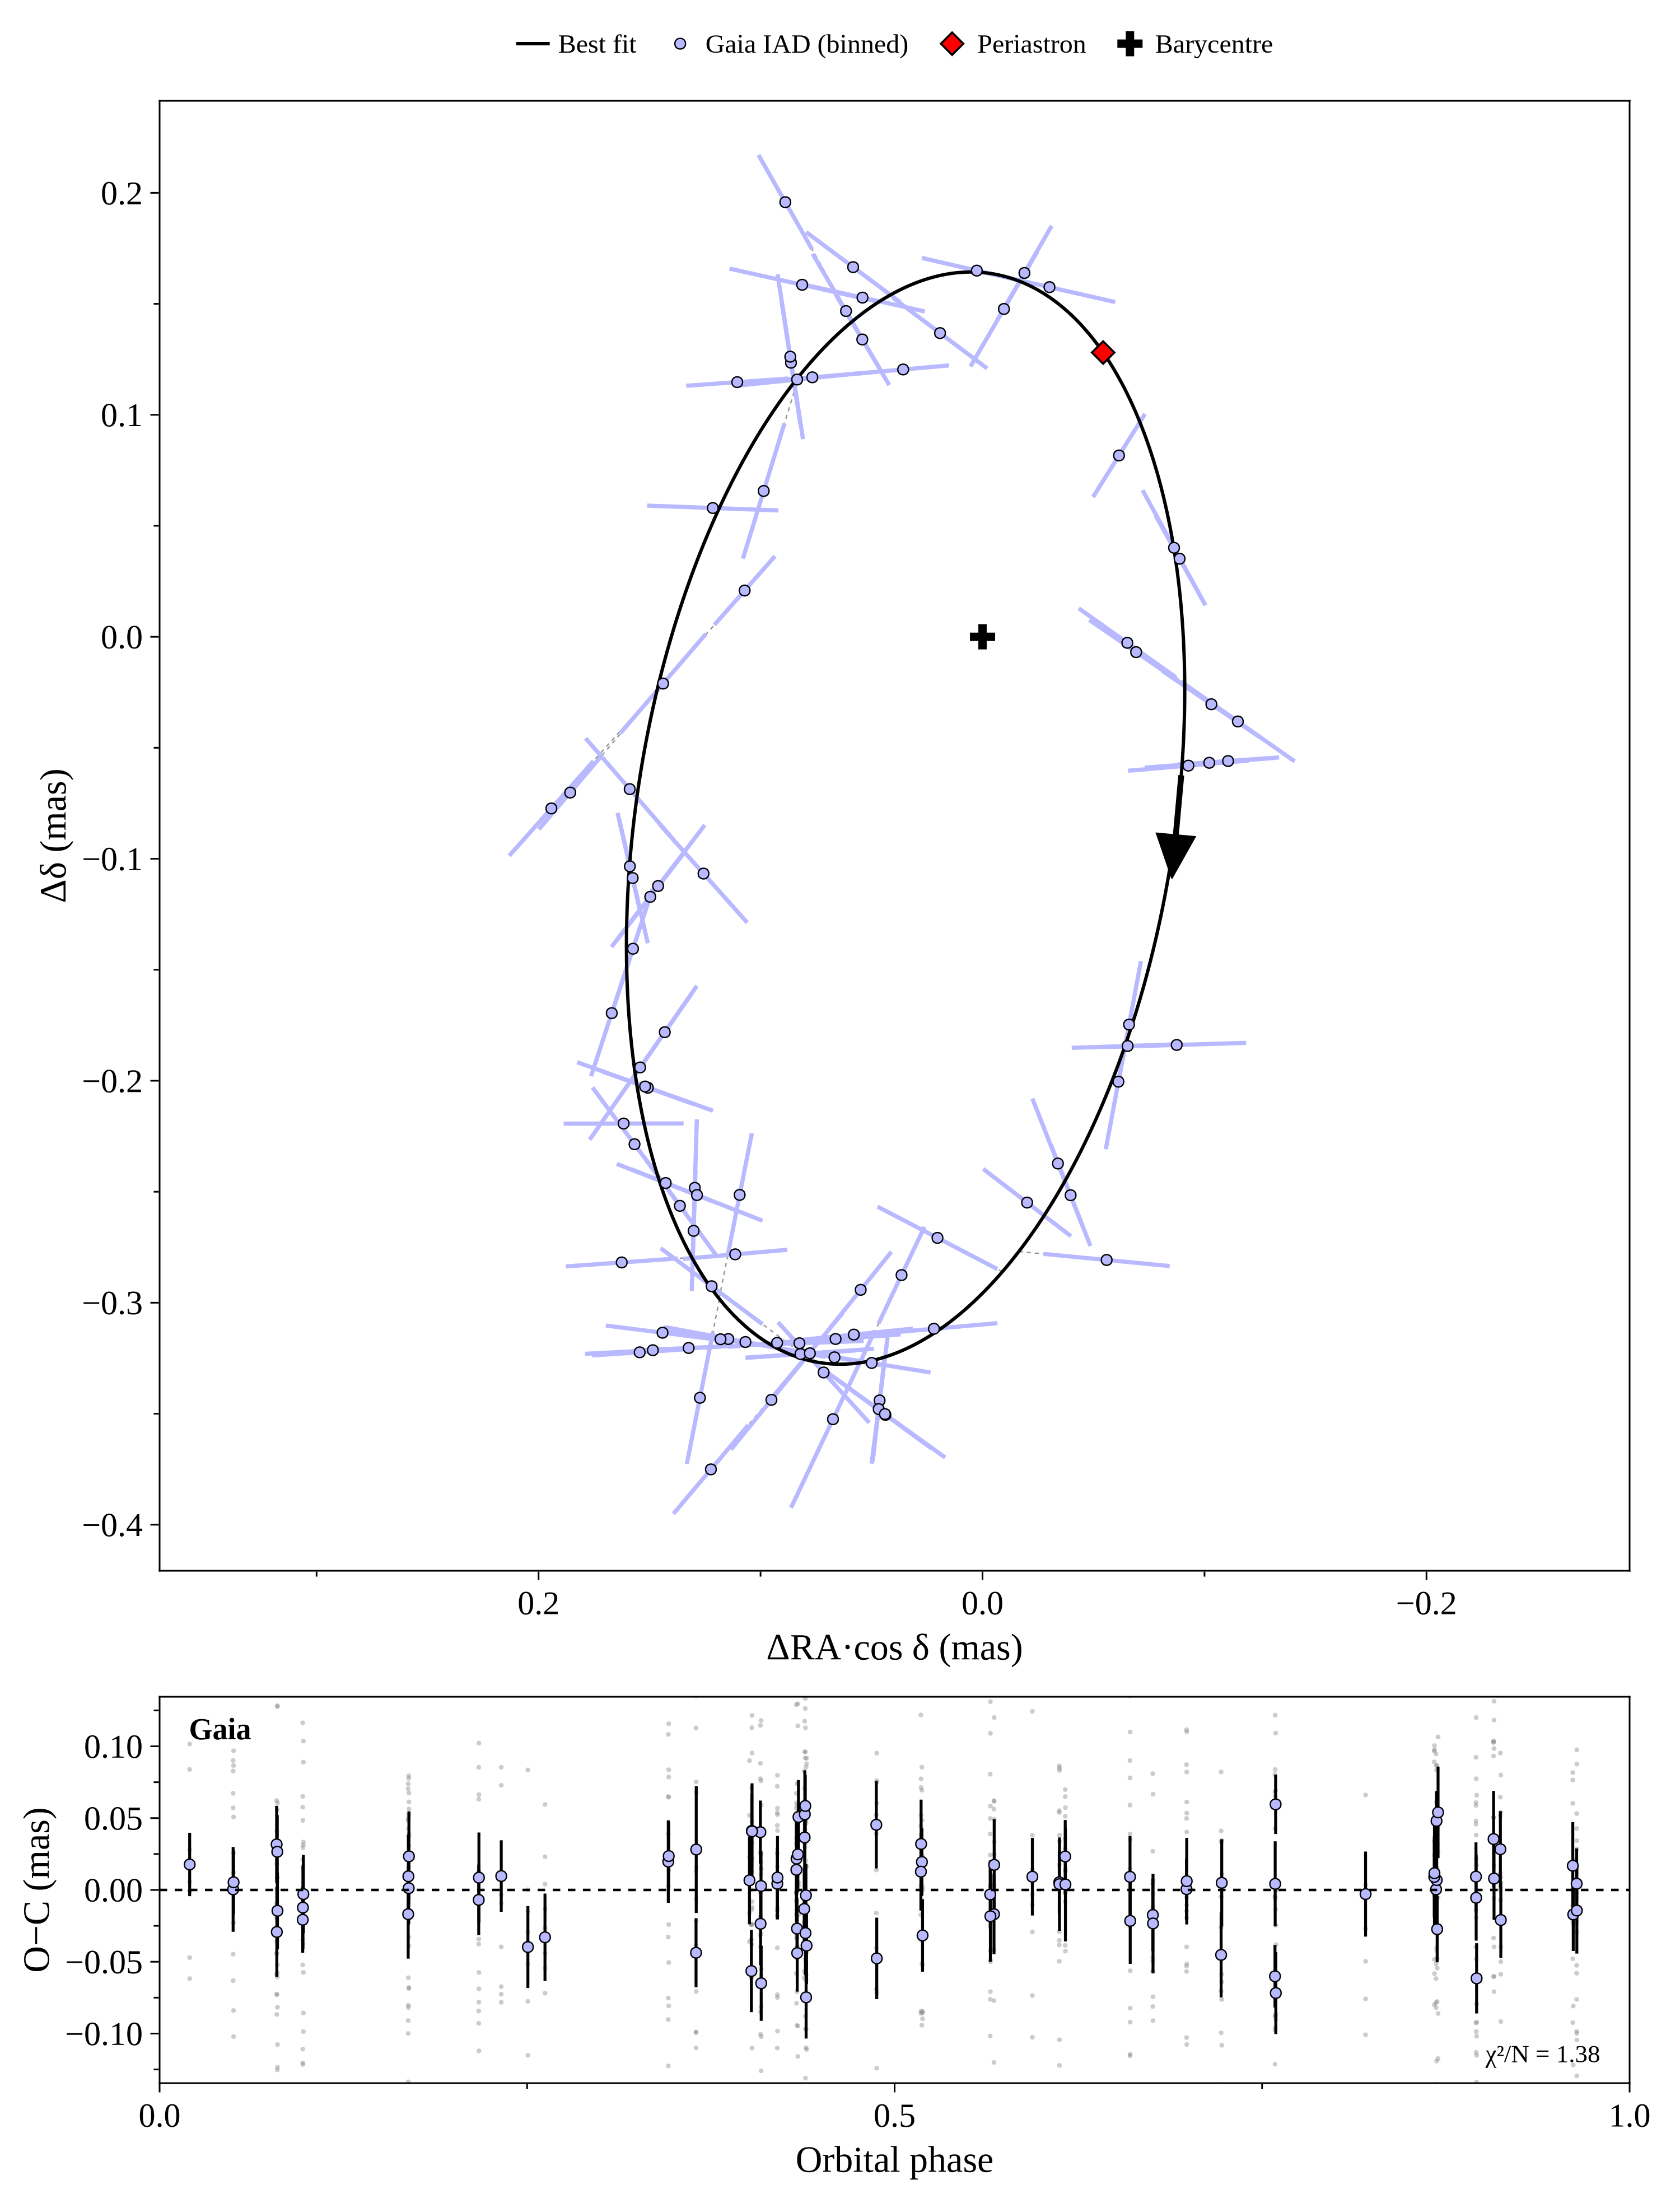

In [10]:
print(res_g4.table())
show(res_g4, "epoch_astrometry_orbit")

Gaia alone gives $M_{\rm sec} = 10.8 \pm 0.4\,M_J$, $i = 121 \pm 2°$ and $e = 0.41 \pm 0.06$, with the abscissae fitted to $\chi^2/N = 1.38$. Stefansson et al. (2025) quote $11.8\,M_J$. No velocities went in: the orbit, its inclination and the mass all come from a 0.25 mas wobble on the sky.

Astrometry alone cannot tell the orbit from its mirror image: $(\Omega, \omega)$ and
$(\Omega + 180°, \omega + 180°)$ trace the same motion on the sky, one with the star
approaching where the other has it receding. The posterior on $\Omega$ is therefore
two modes of equal weight. This is a symmetry of the data, not a sampling failure, and
`PTEmcee` carries it with a move that proposes the mirror orbit directly. The chains
are in `output_dir/chains.nc`, one variable per parameter:

In [11]:
post  = xr.open_dataset("tutorial_out/gaia4_astrometry/chains.nc")
Omega = np.degrees(post["Omega_k1"].values.ravel()) % 360
mode  = (Omega > 90) & (Omega < 270)
print(f"Omega near {np.median(Omega[mode]):.0f} deg: {mode.mean():.3f} of the draws")
print(f"Omega near {np.median(Omega[~mode] - 360 * (Omega[~mode] > 180)):.0f} deg: {1 - mode.mean():.3f}")

Omega near 174 deg: 0.500 of the draws
Omega near -5 deg: 0.500


---
## 4. Radial velocities and astrometry

### 4a. Gaia-4 b

Nereus ships the published HPF, NEID and FIES velocities of Gaia-4 (Stefansson et al.
2025) as a dataset. With the velocities in, the period, eccentricity and $\omega$ come
mostly from the RVs, the inclination and $\Omega$ from the astrometry, and the mass from
both. The priors are those of §3, plus flat jitter priors on [0, 100] m/s for the three
spectrographs. With 5 to 10 velocities each, the default jitter prior of §1 would set the
jitters rather than the residuals.

A fit with astrometry describes the planet by $a$ and $M_{\rm sec}$ rather than $P$
and $K$, so the period is derived through Kepler's third law and the velocities pin a
narrow curved ridge in $(a, M_{\rm sec})$.

The joint posterior is narrow and the prior is wide, so the walkers need a long
burn-in to all reach the $e \approx 0.33$ orbit, and the free jitters add slow
directions of their own: this fit runs 12,000 steps with 24 temperatures. At 8,000
steps, `fit_health` still fails the run on convergence, with one parameter's
split R-hat at 1.06. Check it before quoting a number (§5).

In [12]:
g4 = s.dataset("gaia4")
g4.describe();

gaia4 — Gaia-4
reference: Stefansson et al. 2025, AJ 169, 107 (arXiv:2410.05654) table 5

Radial velocities — 23 points, 3 instruments, 521.9 d baseline
instrument     N   MJD start     MJD end   span (d)  median RV (m/s)   rms (m/s)  median err (m/s)
──────────────────────────────────────────────────────────────────────────────────────────────────
HPF           10   60039.207   60522.117      482.9            -2.20      165.65             15.90
FIES           5   60075.924   60400.049      324.1            -8.30      242.80             12.30
NEID           8   60277.500   60561.151      283.7             0.00      246.56              8.30
──────────────────────────────────────────────────────────────────────────────────────────────────
all           23   60039.207   60561.151      521.9


pt_emcee | ▕████████████████████████▏ | 12000/12000 (100.0%) | acc=0.1640 | β1_acc=0.2840 | min_swap=0.2830 | Rhat=1.001/1.001 | ESS=100493/119255 | nevals=28802400 | elapsed 2m16s        
[ Info: pt_emcee: moved the seam of Omega_k1 to the emptiest arc of its posterior; window now [1.83, 8.12). Still one full period under the same uniform prior, so this relabels the circle and changes neither the posterior nor the evidence.
[ Info: pt_emcee: burn-in moved 38 stranded walker state(s) onto their rung's mode (38 at β = 1), all from a region whose total posterior mass is bounded below e⁻¹⁰ of the mode's. The recorded chain is ordinary MCMC.
┌ Warning: sample_pt_emcee: bridge and mode-Laplace disagree by 32.3 nats. Reporting bridge (it is the validated one), but CHECK THE POSTERIOR IS NOT MULTIMODAL before quoting it — a single Gaussian reference cannot cover multiple modes and overlap will not tell you so.
│   bridge = 541.0194153087575
│   laplace = 508.7393979537654
│   overlap = 0.9999

<JobResult status=ok log_z=541.00 elapsed=139s 14 params 3 figures>

fitted parameters (14)
  M_sec_k1    0.01020 +0.00023 -0.00021  M_sun  = 10.7 M_jup
  Mo_k1         0.495   +0.091   -0.085  rad    = 28.34 deg
  Omega_k1      6.166   +0.035   -0.035  rad    = 353.30 deg
  a_k1         1.1760  +0.0015  -0.0014  AU
  gamma_FIES       79      +18      -20  m/s
  gamma_HPF       -40      +12      -11  m/s
  gamma_NEID      -20      +13      -12  m/s
  inc_k1        2.116   +0.033   -0.032  rad    = 121.25 deg
  plx         13.6249  +0.0059  -0.0059  mas
  secosw_k1    -0.528   +0.031   -0.029
  sesinw_k1    -0.230   +0.056   -0.053
  sigma_FIES       37      +25      -16  m/s
  sigma_HPF        31      +16      -11  m/s
  sigma_NEID     17.4     +9.8     -6.5  m/s

derived quantities (3)
  a_au_k1       1.1760 +0.0015 -0.0014  AU
  ecc_k1         0.334  +0.027  -0.025
  omega_deg_k1  -156.5    +5.7    -5.8  deg  multimodal
models/epoch_astrometry_orbit_K1


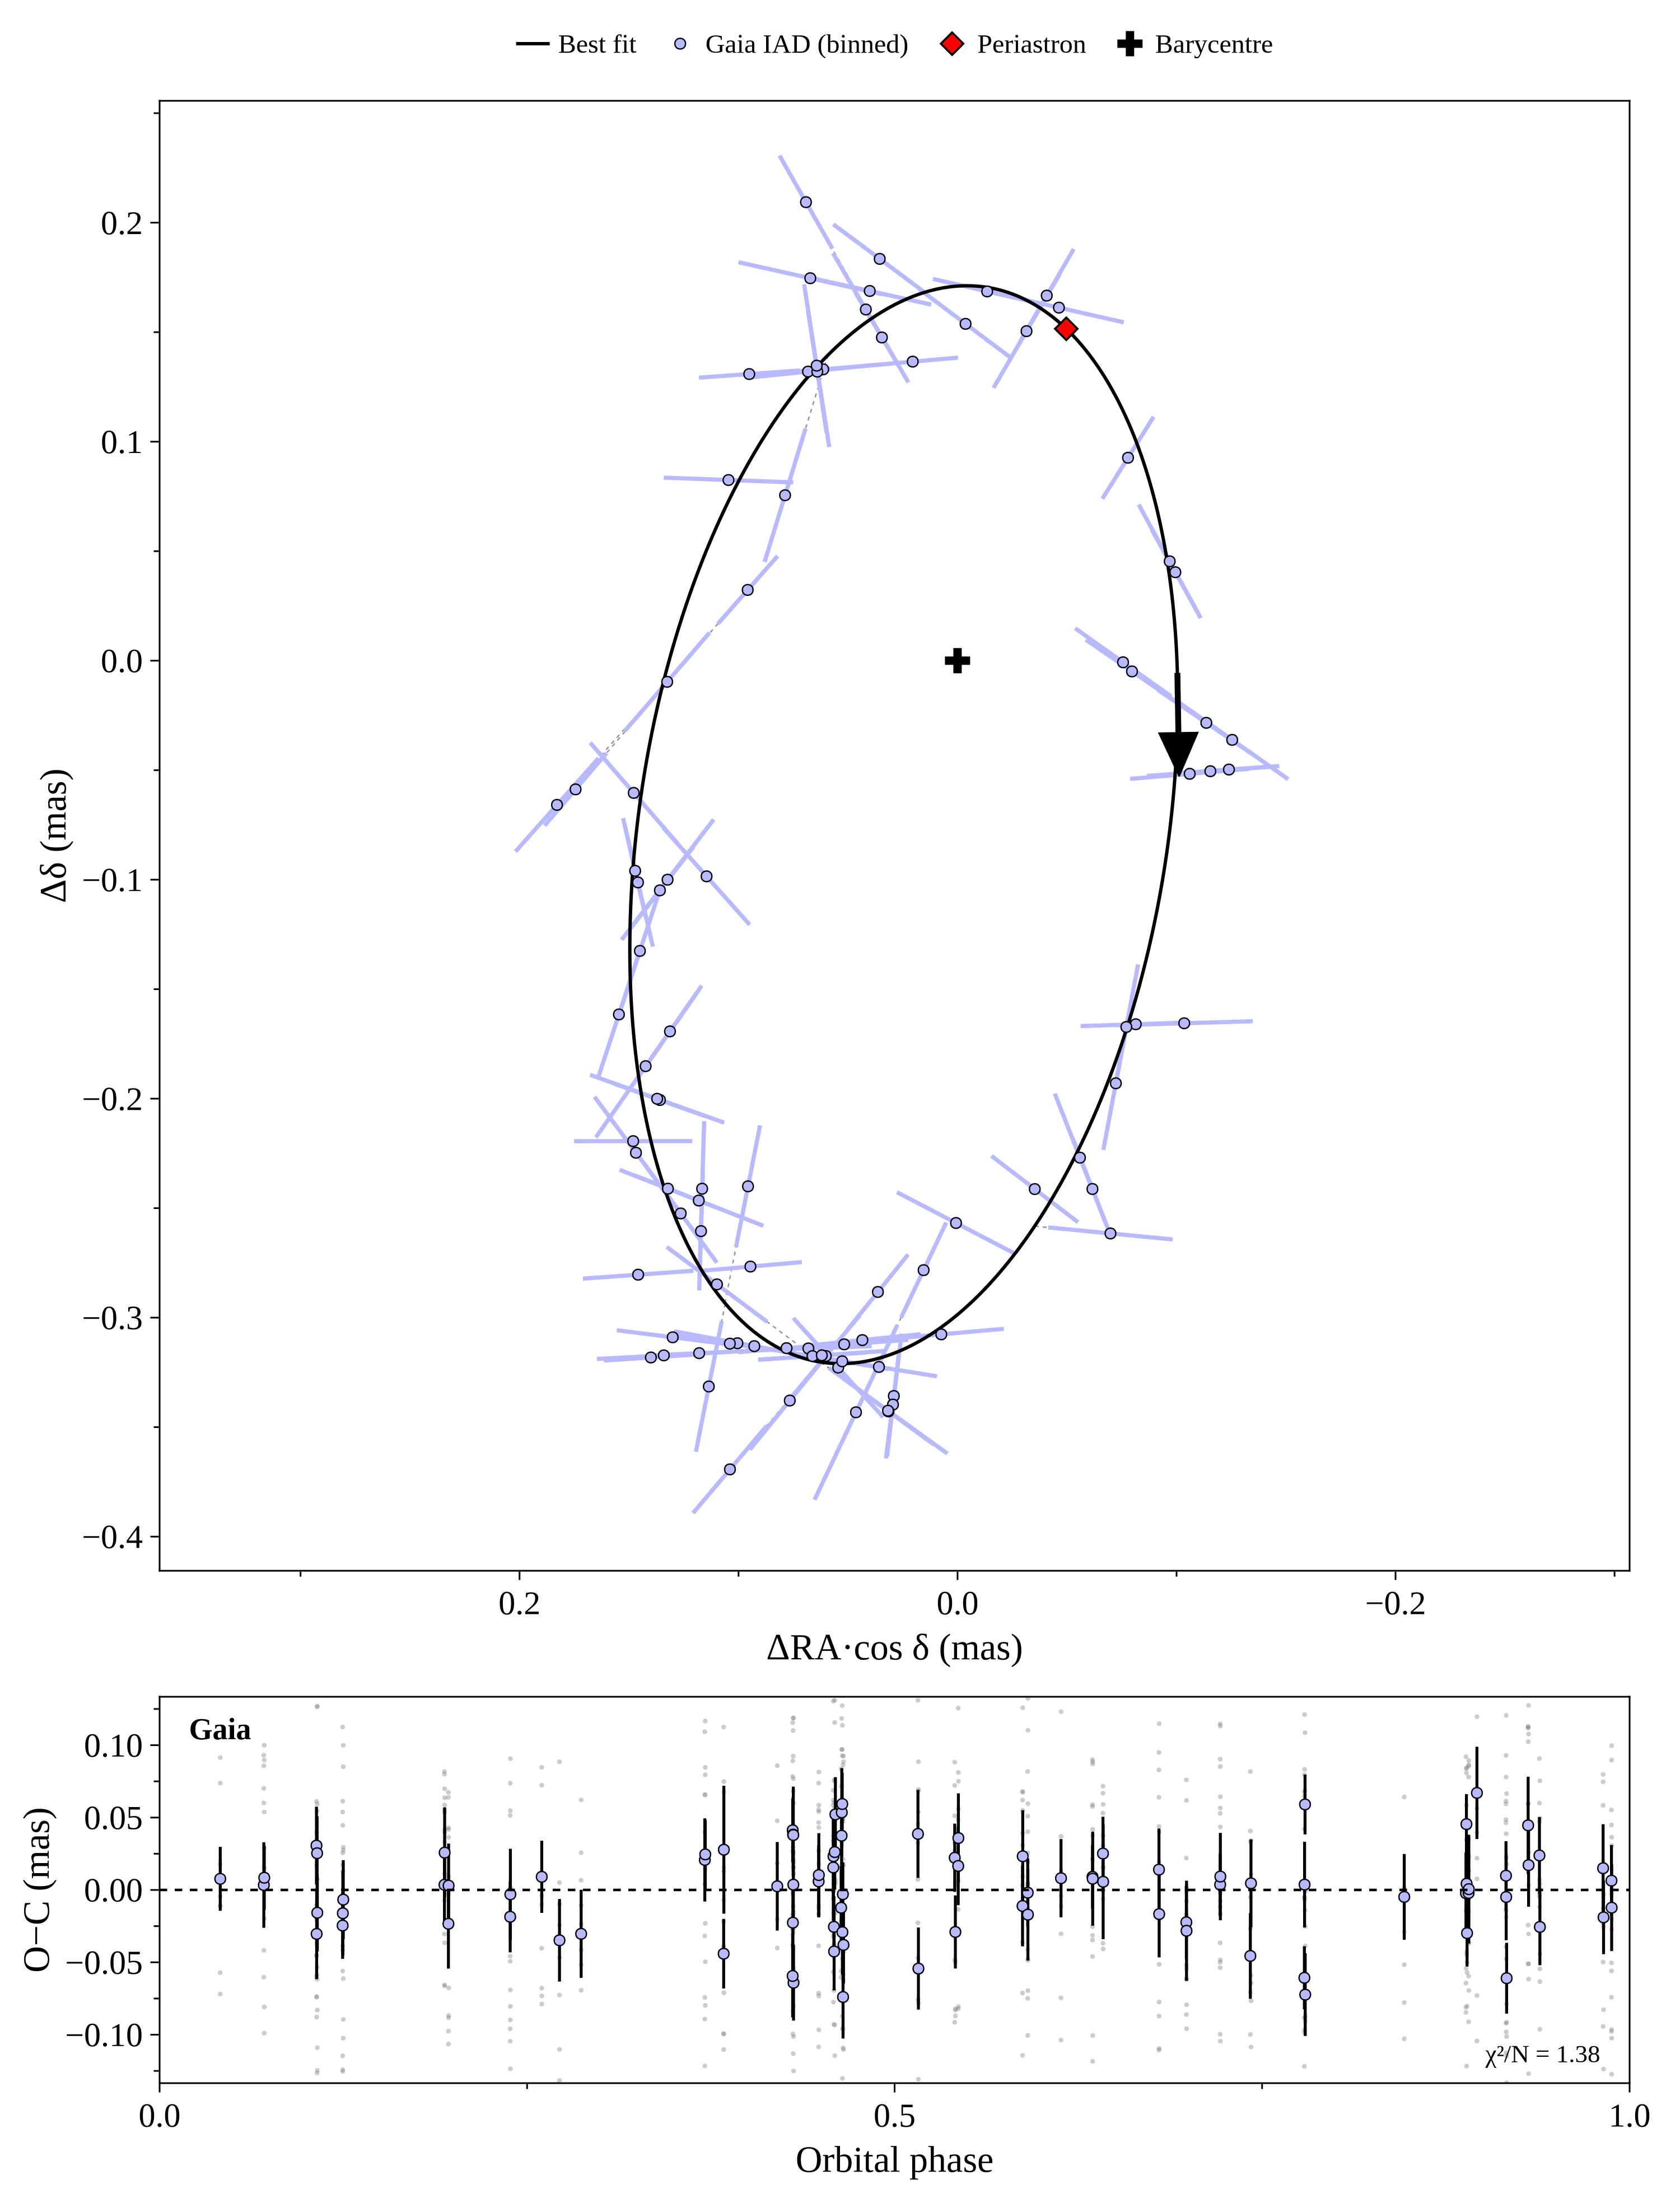

models/RV_phasefold_K1


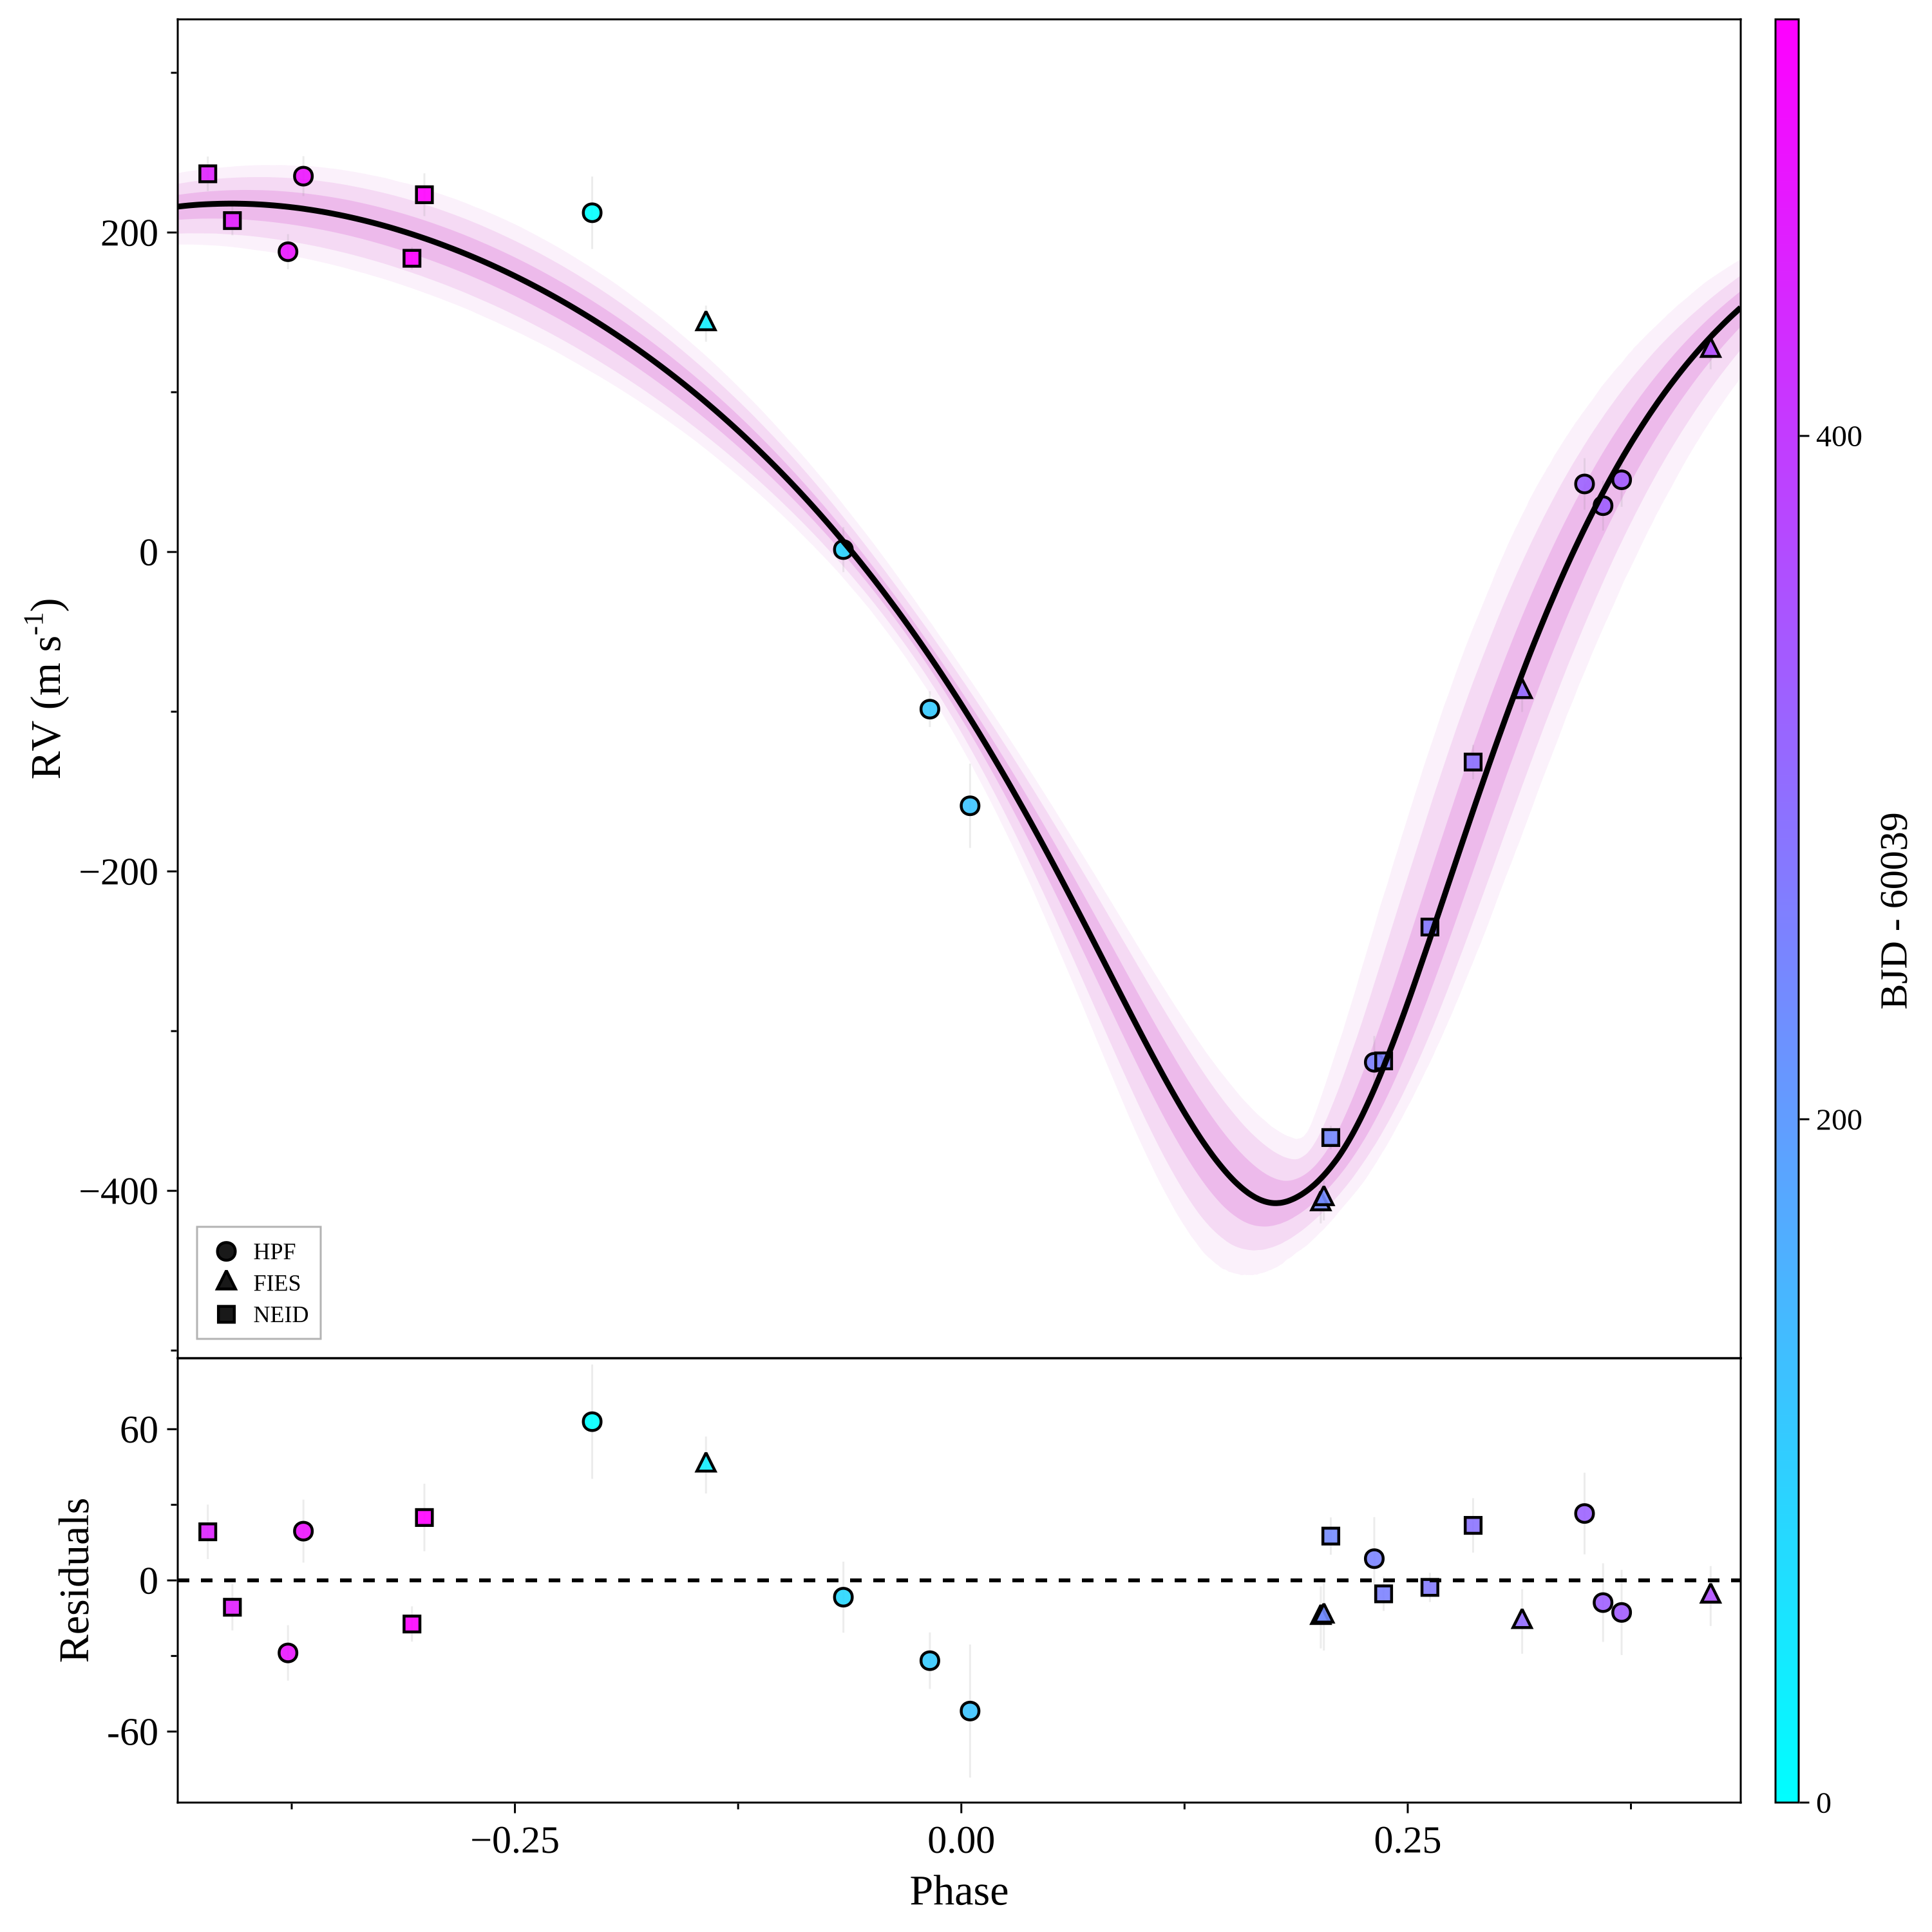

In [13]:
JITTER_G4 = {f"sigma_{inst}": {"type": "uniform", "lo": 0.0, "hi": 100.0}  # m/s
             for inst in ("HPF", "FIES", "NEID")}

res_g4j = s.fit_joint(g4.rv, Astrometry(iad=[GAIA4]), planets=1,
                      priors={**PRIORS_G4, **JITTER_G4}, M_s=0.644,
                      engine=ptemcee(n_temps=24, n_steps=12000),
                      plots=["epoch_astrometry_orbit", "rv_phasefold", "corner"],
                      output_dir="tutorial_out/gaia4_joint")
print(res_g4j.table())
show(res_g4j, "epoch_astrometry_orbit", "RV_phasefold")

With the velocities in, the mass is $10.7 \pm 0.2\,M_J$, half the error of §3, the eccentricity tightens from $0.41 \pm 0.06$ to $0.334 \pm 0.026$, and $i = 121.2 \pm 1.9°$. Stefansson et al. (2025) quote $11.8\,M_J$. $\Omega$ is now a single mode at 353°: the velocities say which side of the orbit is coming towards us, which astrometry alone cannot.

The jitters come out at 31, 37 and 17 m/s for HPF, FIES and NEID, two to three times the quoted errors, and with them the velocities fit at $\chi^2/{\rm dof} = 0.84$. Under the default prior they stay near 11 m/s and the velocities sit at $\chi^2/{\rm dof} = 2.2$.

### 4b. HD 114762 b: breaking $\sin i$

HD 114762 b was announced in 1989 (Latham et al.) as the first substellar companion
candidate, with $M \sin i \approx 11\,M_J$. Whether it is a brown dwarf or a star
depends on one number the velocities cannot give: the inclination.

| channel | data |
|---|---|
| RV | Keck/HIRES and Lick, 29 years (California Legacy Survey, Rosenthal et al. 2021) |
| Gaia DR4 | pre-release epoch astrometry |

In [14]:
hd = s.dataset("hd114762")
hd.describe();

DR4 = {"catalogue": "gaia_dr4", "source_id": 3937211745905473024}

hd114762 — HD 114762
reference: Rosenthal et al. 2021, ApJS 255, 8 (California Legacy)

Radial velocities — 59 points, 2 instruments, 10714.8 d baseline
instrument     N   MJD start     MJD end   span (d)  median RV (m/s)   rms (m/s)  median err (m/s)
──────────────────────────────────────────────────────────────────────────────────────────────────
Lick          35   47964.464   54864.543     6900.1           373.24      419.53             14.87
HIRES         24   56640.653   58679.237     2038.6            96.27      355.00              1.72
──────────────────────────────────────────────────────────────────────────────────────────────────
all           59   47964.464   58679.237    10714.8


First the velocities alone: the 1989 measurement, redone with 29 years of data. The
period has been known since then, so it is bracketed.

pt_emcee | ▕████████████████████████▏ | 3000/3000 (100.0%) | acc=0.2430 | β1_acc=0.3760 | min_swap=0.0330 | Rhat=1.003/1.004 | ESS=26702/38337 | nevals=4801600 | elapsed 7s        
[ Info: pt_emcee: burn-in moved 482 stranded walker state(s) onto their rung's mode (31 at β = 1), all from a region whose total posterior mass is bounded below e⁻¹⁰ of the mode's. The recorded chain is ordinary MCMC.
┌ Warning: sample_pt_emcee: bridge and mode-Laplace disagree by 22.4 nats. Reporting bridge (it is the validated one), but CHECK THE POSTERIOR IS NOT MULTIMODAL before quoting it — a single Gaussian reference cannot cover multiple modes and overlap will not tell you so.
│   bridge = -254.6544587876682
│   laplace = -277.06517753961225
│   overlap = 1.0
└ @ Nereus /work/bundle/depot/dev/Nereus/src/samplers/pt_emcee.jl:1303
┌ Warning: sample_pt_emcee: the TEMPERED stack (TI/TI+/SS+/H+ in `evidence`) is 188.4 nats from the reported log_evidence — the phase-transition signature (min swap accept = 0

<JobResult status=ok log_z=-254.65 elapsed=8s 9 params 1 figures>

fitted parameters (9)
  K_k1           620.32    +0.84    -0.85  m/s
  Mo_k1          4.4054  +0.0045  -0.0044  rad  = 252.41 deg
  P_k1         83.91707 +0.00091 -0.00092  d
  gamma_HIRES    -93.58    +0.51    -0.51  m/s
  gamma_Lick      194.9     +2.7     -2.6  m/s
  secosw_k1     -0.5362  +0.0012  -0.0013
  sesinw_k1     -0.2374  +0.0017  -0.0017
  sigma_HIRES      1.12    +0.67    -0.67  m/s
  sigma_Lick        6.1     +3.2     -3.3  m/s

derived quantities (6)
  P_yr_k1         0.2297524 +0.0000025 -0.0000025  yr
  a_au_k1             0.352     +0.011     -0.012  AU
  ecc_k1             0.3439    +0.0012    -0.0012
  msini_earth_k1       3521       +231       -236  M_earth
  msini_jup_k1        11.08      +0.73      -0.74  M_jup
  omega_deg_k1      -156.12      +0.18      -0.18  deg
models/RV_phasefold_K1


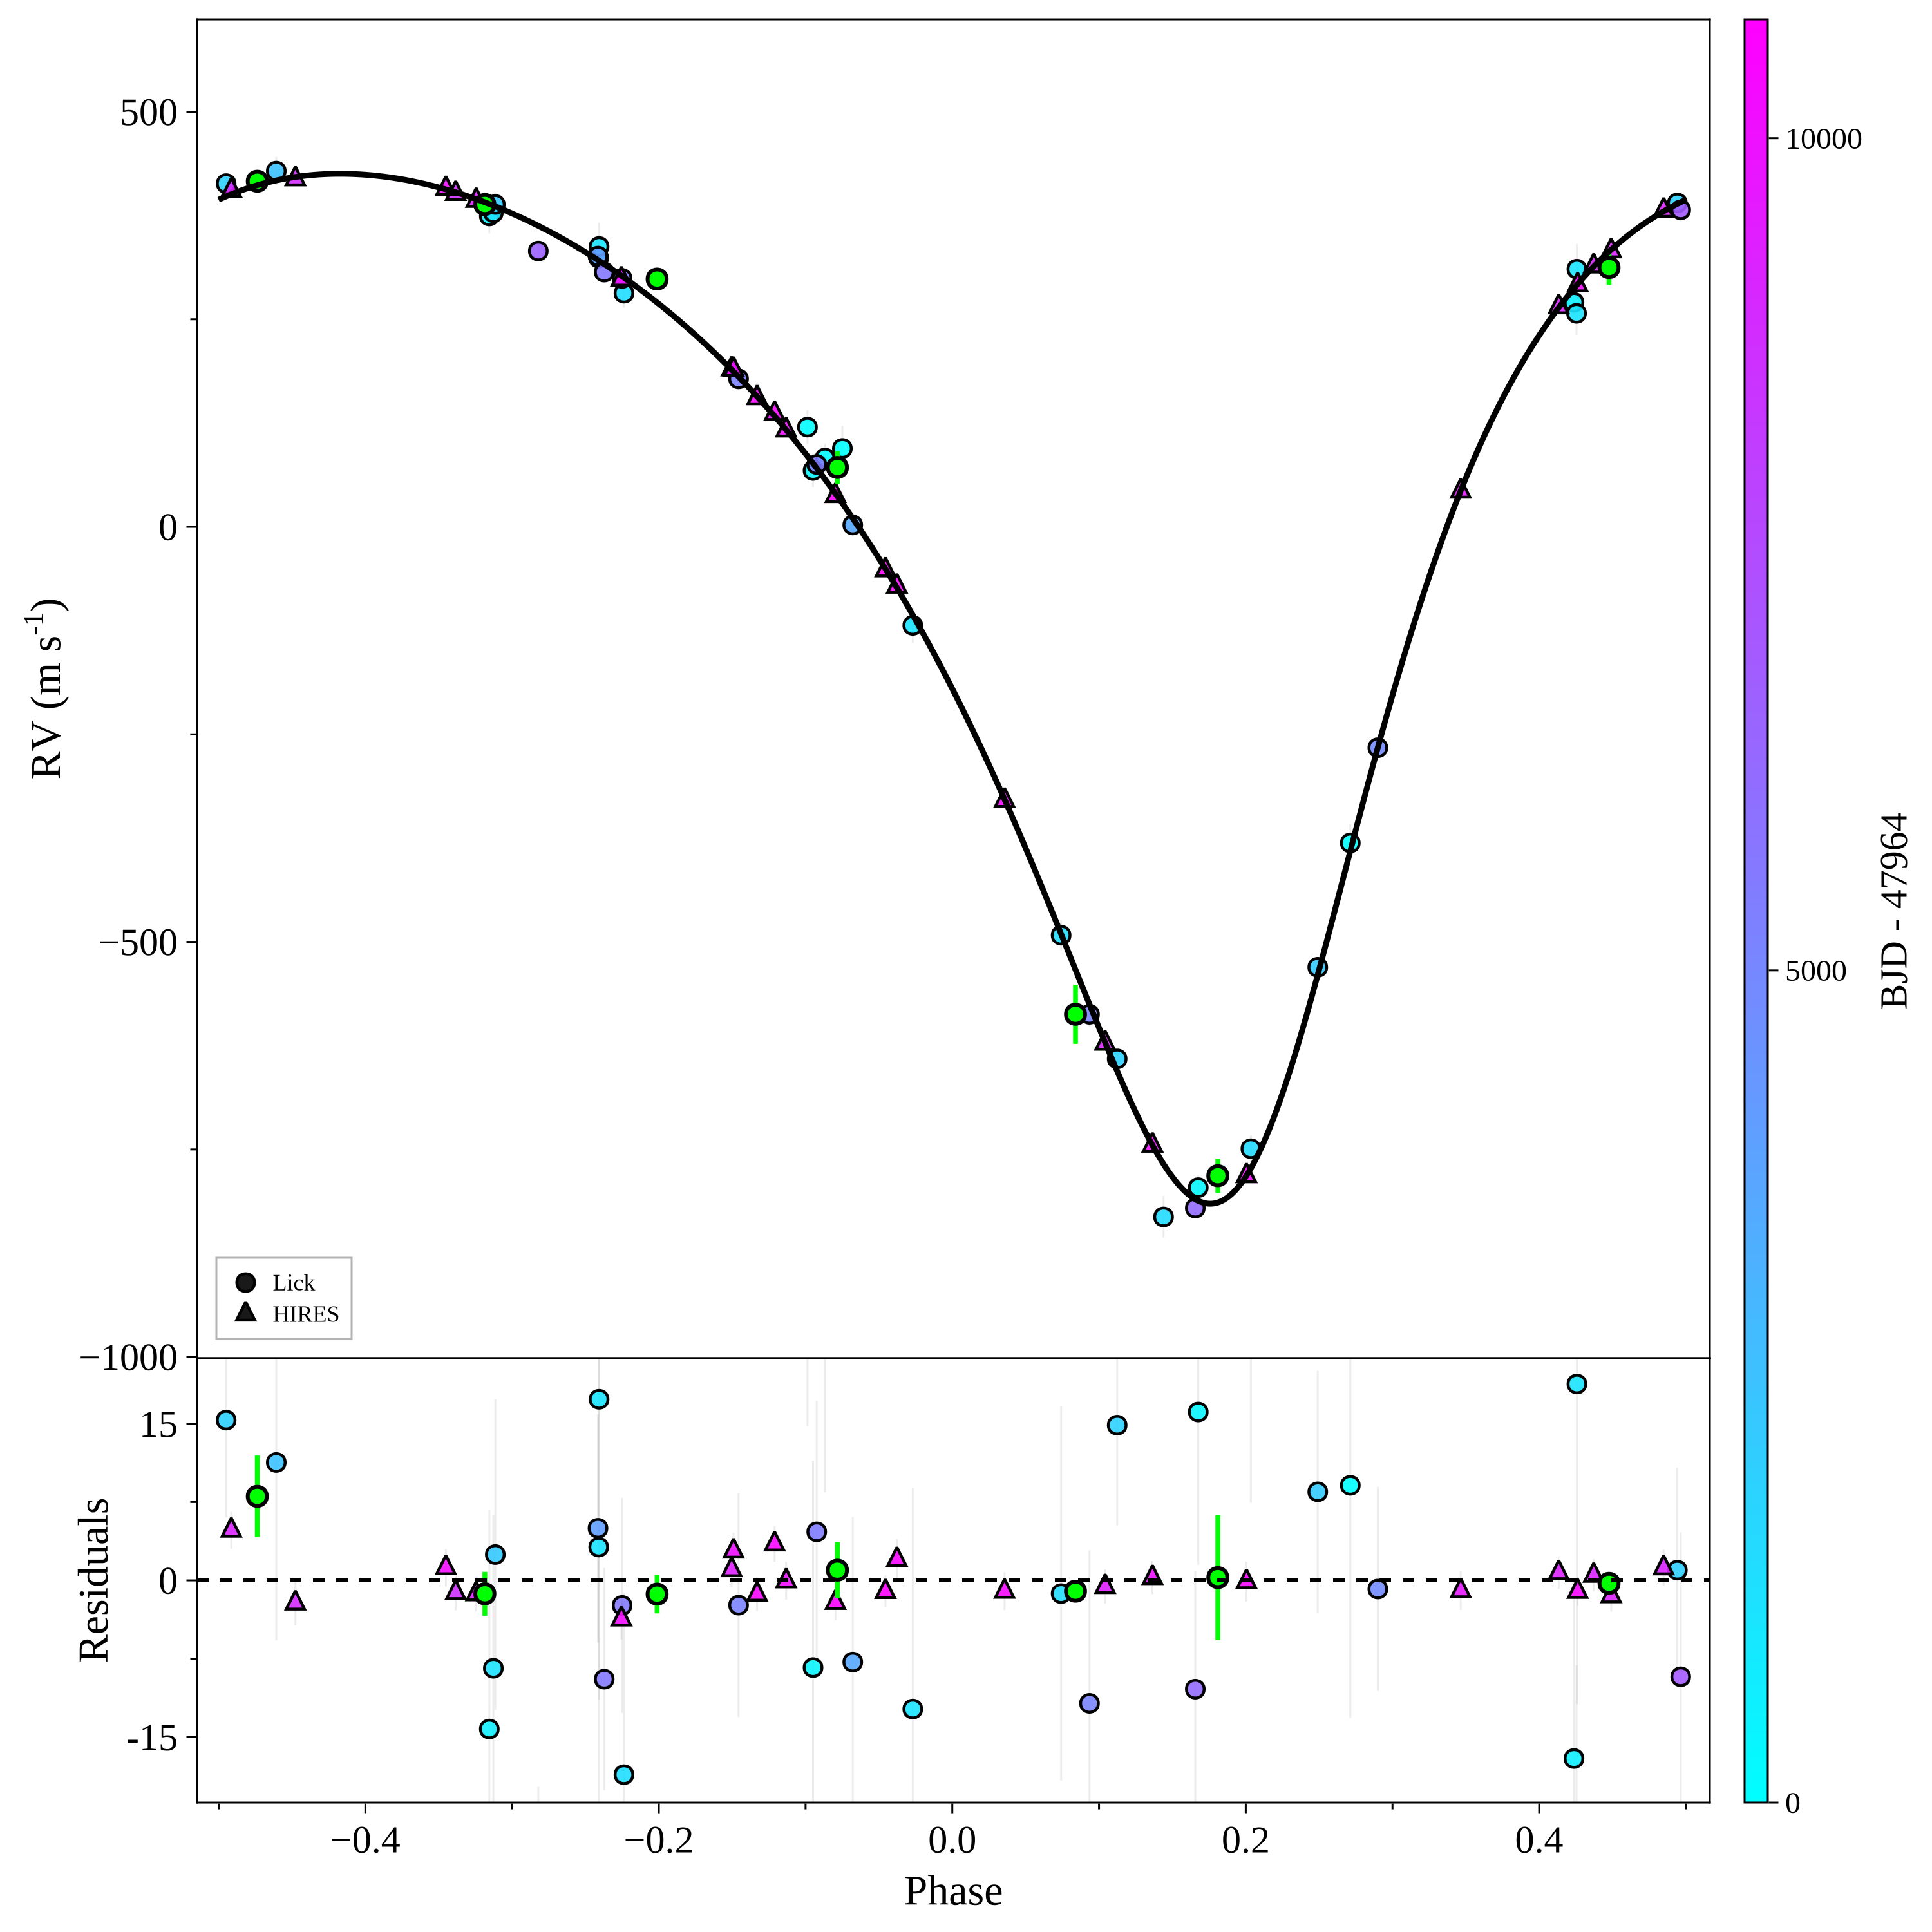

In [15]:
res_hd_rv = s.fit_rv(hd.rv, planets=1,
                     priors={"P_k1": {"type": "loguniform", "lo": 60.0, "hi": 105.0}},
                     M_s=0.83, engine=ptemcee(), plots=["rv_phasefold"],
                     output_dir="tutorial_out/hd114762_rv")
print(res_hd_rv.table())
show(res_hd_rv, "RV_phasefold")

Now jointly with Gaia. The priors follow §3; the mass prior reaches $0.5\,M_\odot$ on
purpose, because a prior that stopped at planetary masses would decide the answer
before the data could. The joint posterior is again narrow against a wide prior, so
this fit also runs 24 temperatures, with 8,000 steps.

pt_emcee | ▕████████████████████████▏ | 8000/8000 (100.0%) | acc=0.1840 | β1_acc=0.3360 | min_swap=0.1410 | Rhat=1.001/1.001 | ESS=108467/126502 | nevals=19202400 | elapsed 1m27s        
[ Info: pt_emcee: burn-in moved 1548 stranded walker state(s) onto their rung's mode (32 at β = 1), all from a region whose total posterior mass is bounded below e⁻¹⁰ of the mode's. The recorded chain is ordinary MCMC.
┌ Warning: sample_pt_emcee: the TEMPERED stack (TI/TI+/SS+/H+ in `evidence`) is 401.9 nats from the reported log_evidence — the phase-transition signature (min swap accept = 0.141). Those four share one mean_logL array, so their agreeing with EACH OTHER is not a check.
│   tempered = -2743.874809810146
│   reported = -2342.005886274885
└ @ Nereus /work/bundle/depot/dev/Nereus/src/samplers/pt_emcee.jl:1333
post-fit | ▕███████░░░░░░░░░░░░░░░░░▏ | 2/7 (28.6%) | stage=loo | elapsed 0s             
[ Info: No source provided for samples; variables are assumed to be from a Markov Chain. If the

<JobResult status=ok log_z=-2342.01 elapsed=89s 12 params 3 figures>

fitted parameters (12)
  M_sec_k1      0.1991  +0.0010  -0.0010  M_sun  = 209 M_jup
  Mo_k1         4.4042  +0.0045  -0.0045  rad    = 252.34 deg
  Omega_k1      5.8193  +0.0056  -0.0055  rad    = 333.42 deg
  a_k1         0.37872 +0.00012 -0.00013  AU
  gamma_HIRES   -93.56    +0.51    -0.50  m/s
  gamma_Lick     194.8     +2.7     -2.6  m/s
  inc_k1       0.06136 +0.00028 -0.00028  rad    = 3.52 deg
  plx           25.297   +0.011   -0.011  mas
  secosw_k1    -0.5359  +0.0013  -0.0013
  sesinw_k1    -0.2373  +0.0017  -0.0017
  sigma_HIRES     1.13    +0.67    -0.65  m/s
  sigma_Lick       6.2     +3.2     -3.3  m/s

derived quantities (3)
  a_au_k1       0.37872 +0.00012 -0.00013  AU
  ecc_k1         0.3435  +0.0012  -0.0012
  omega_deg_k1  -156.12    +0.18    -0.18  deg
models/epoch_astrometry_orbit_K1


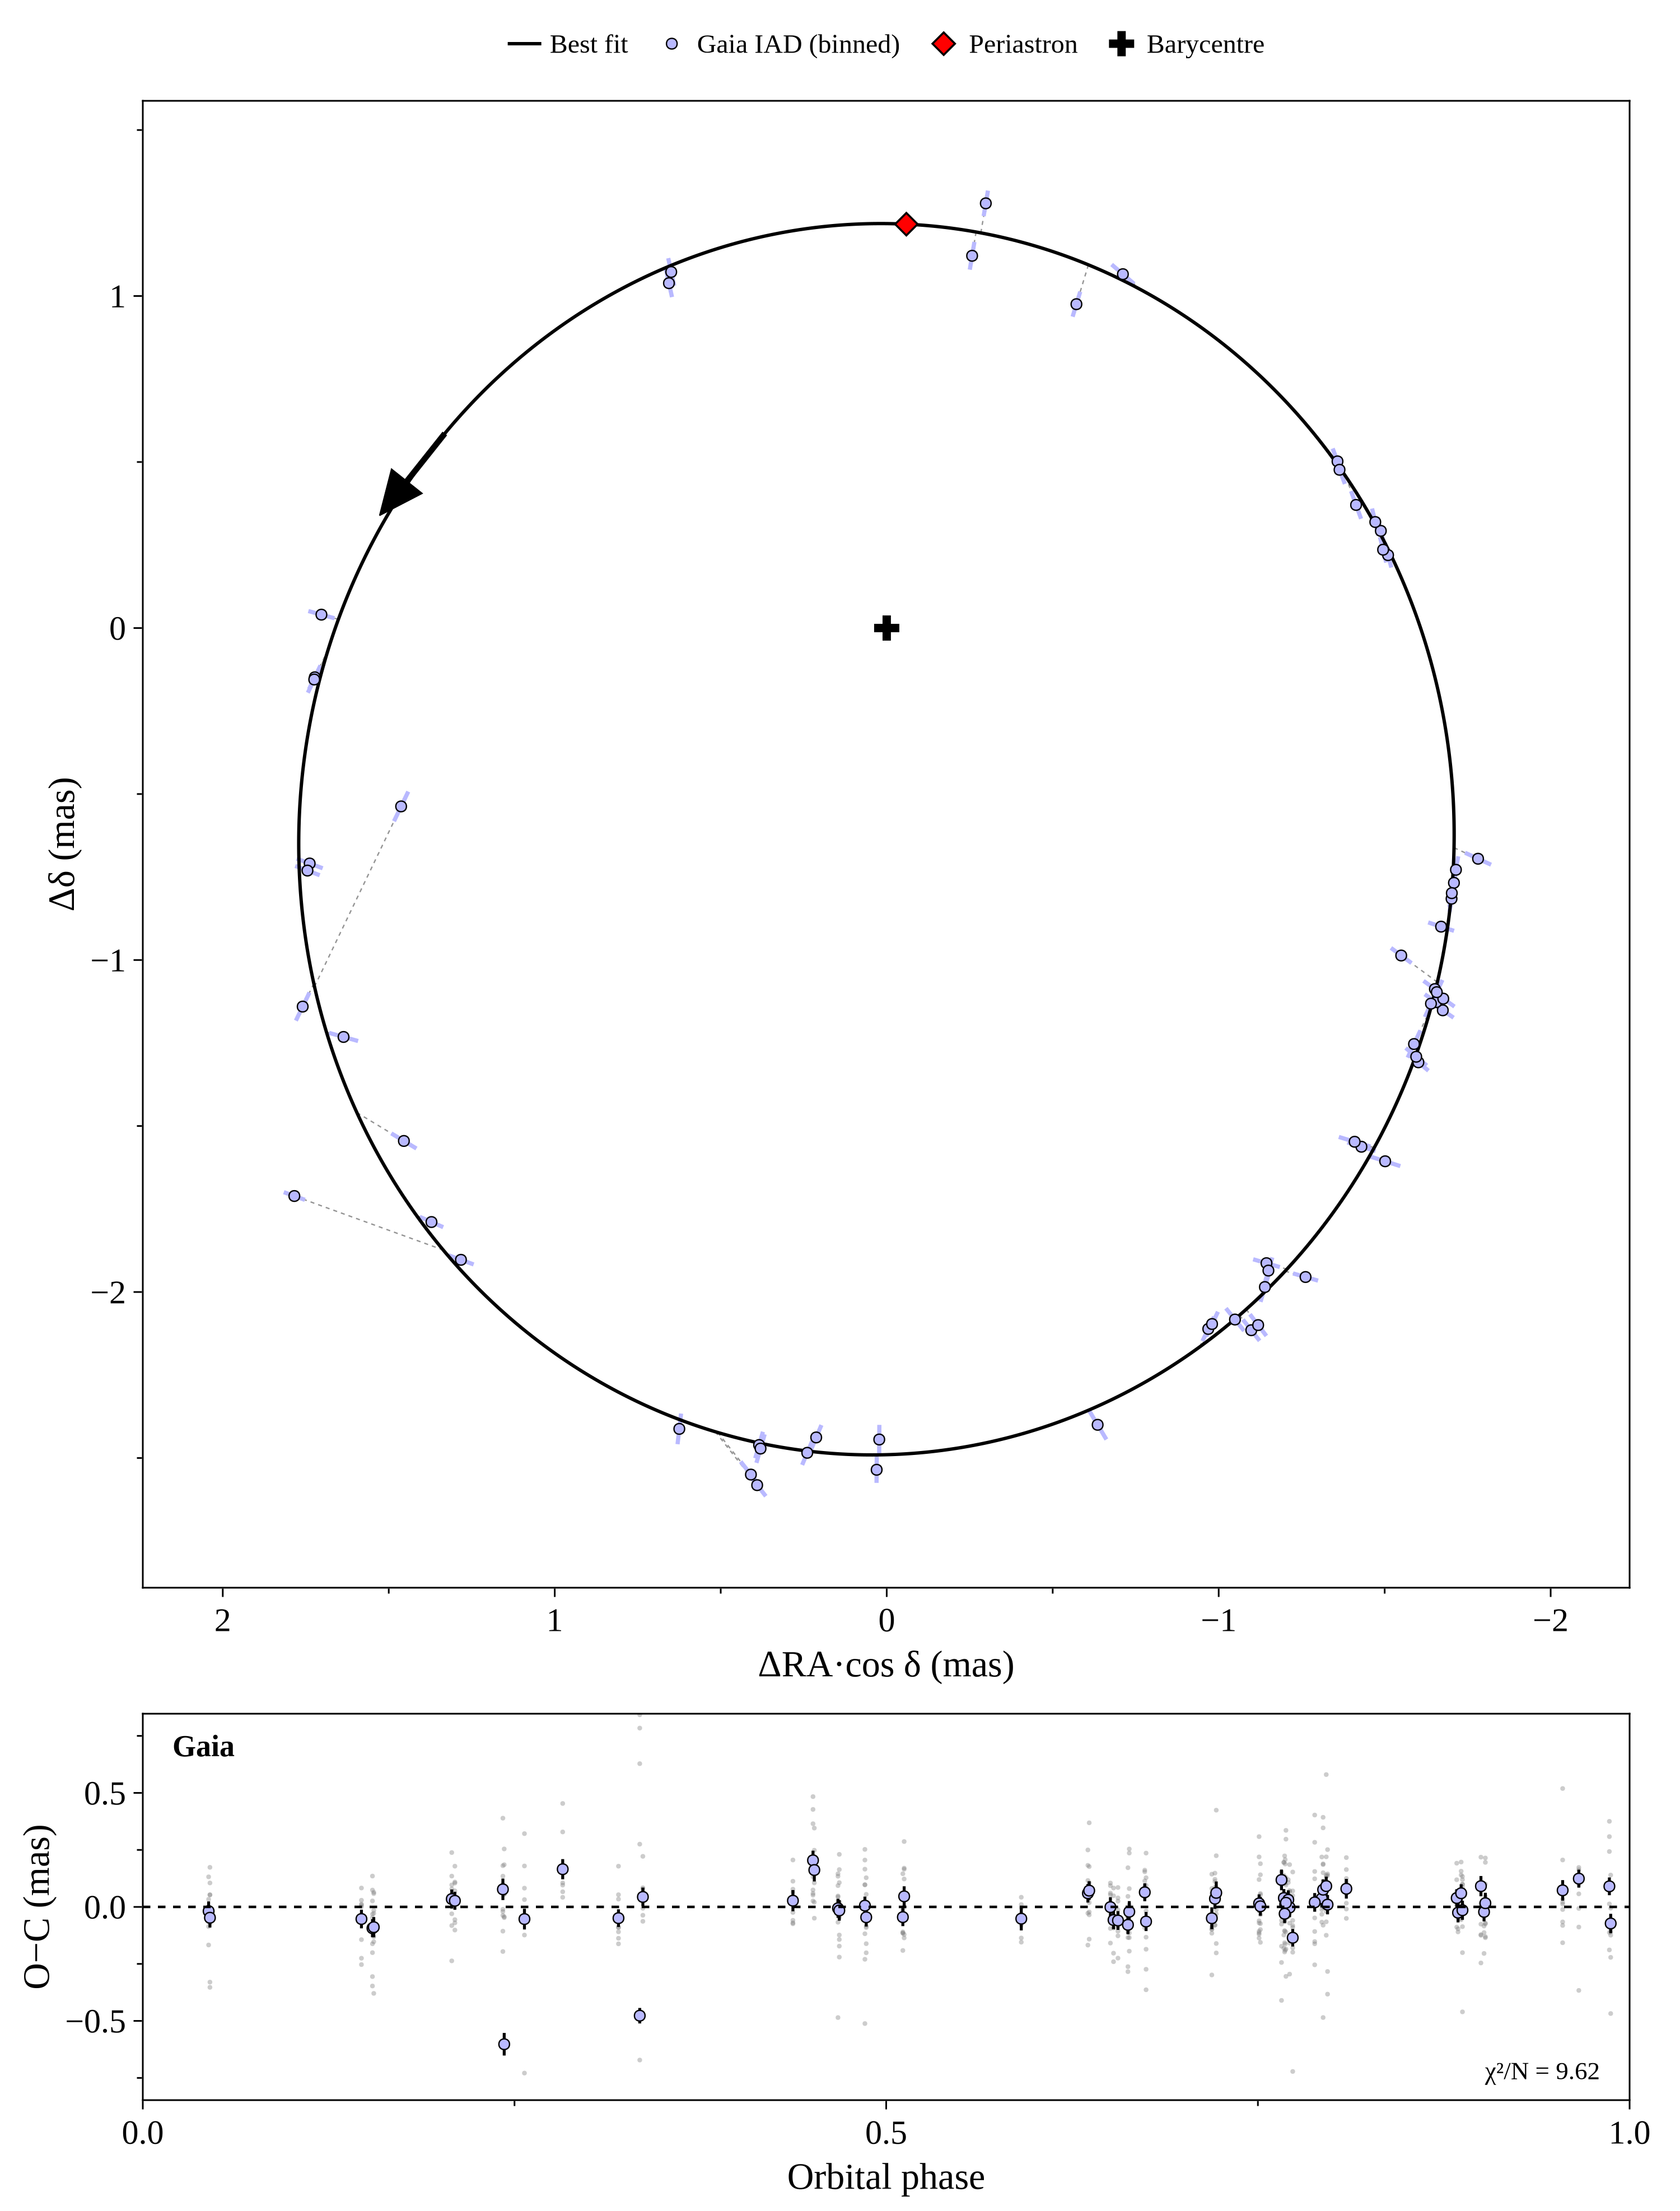

models/iad_residuals


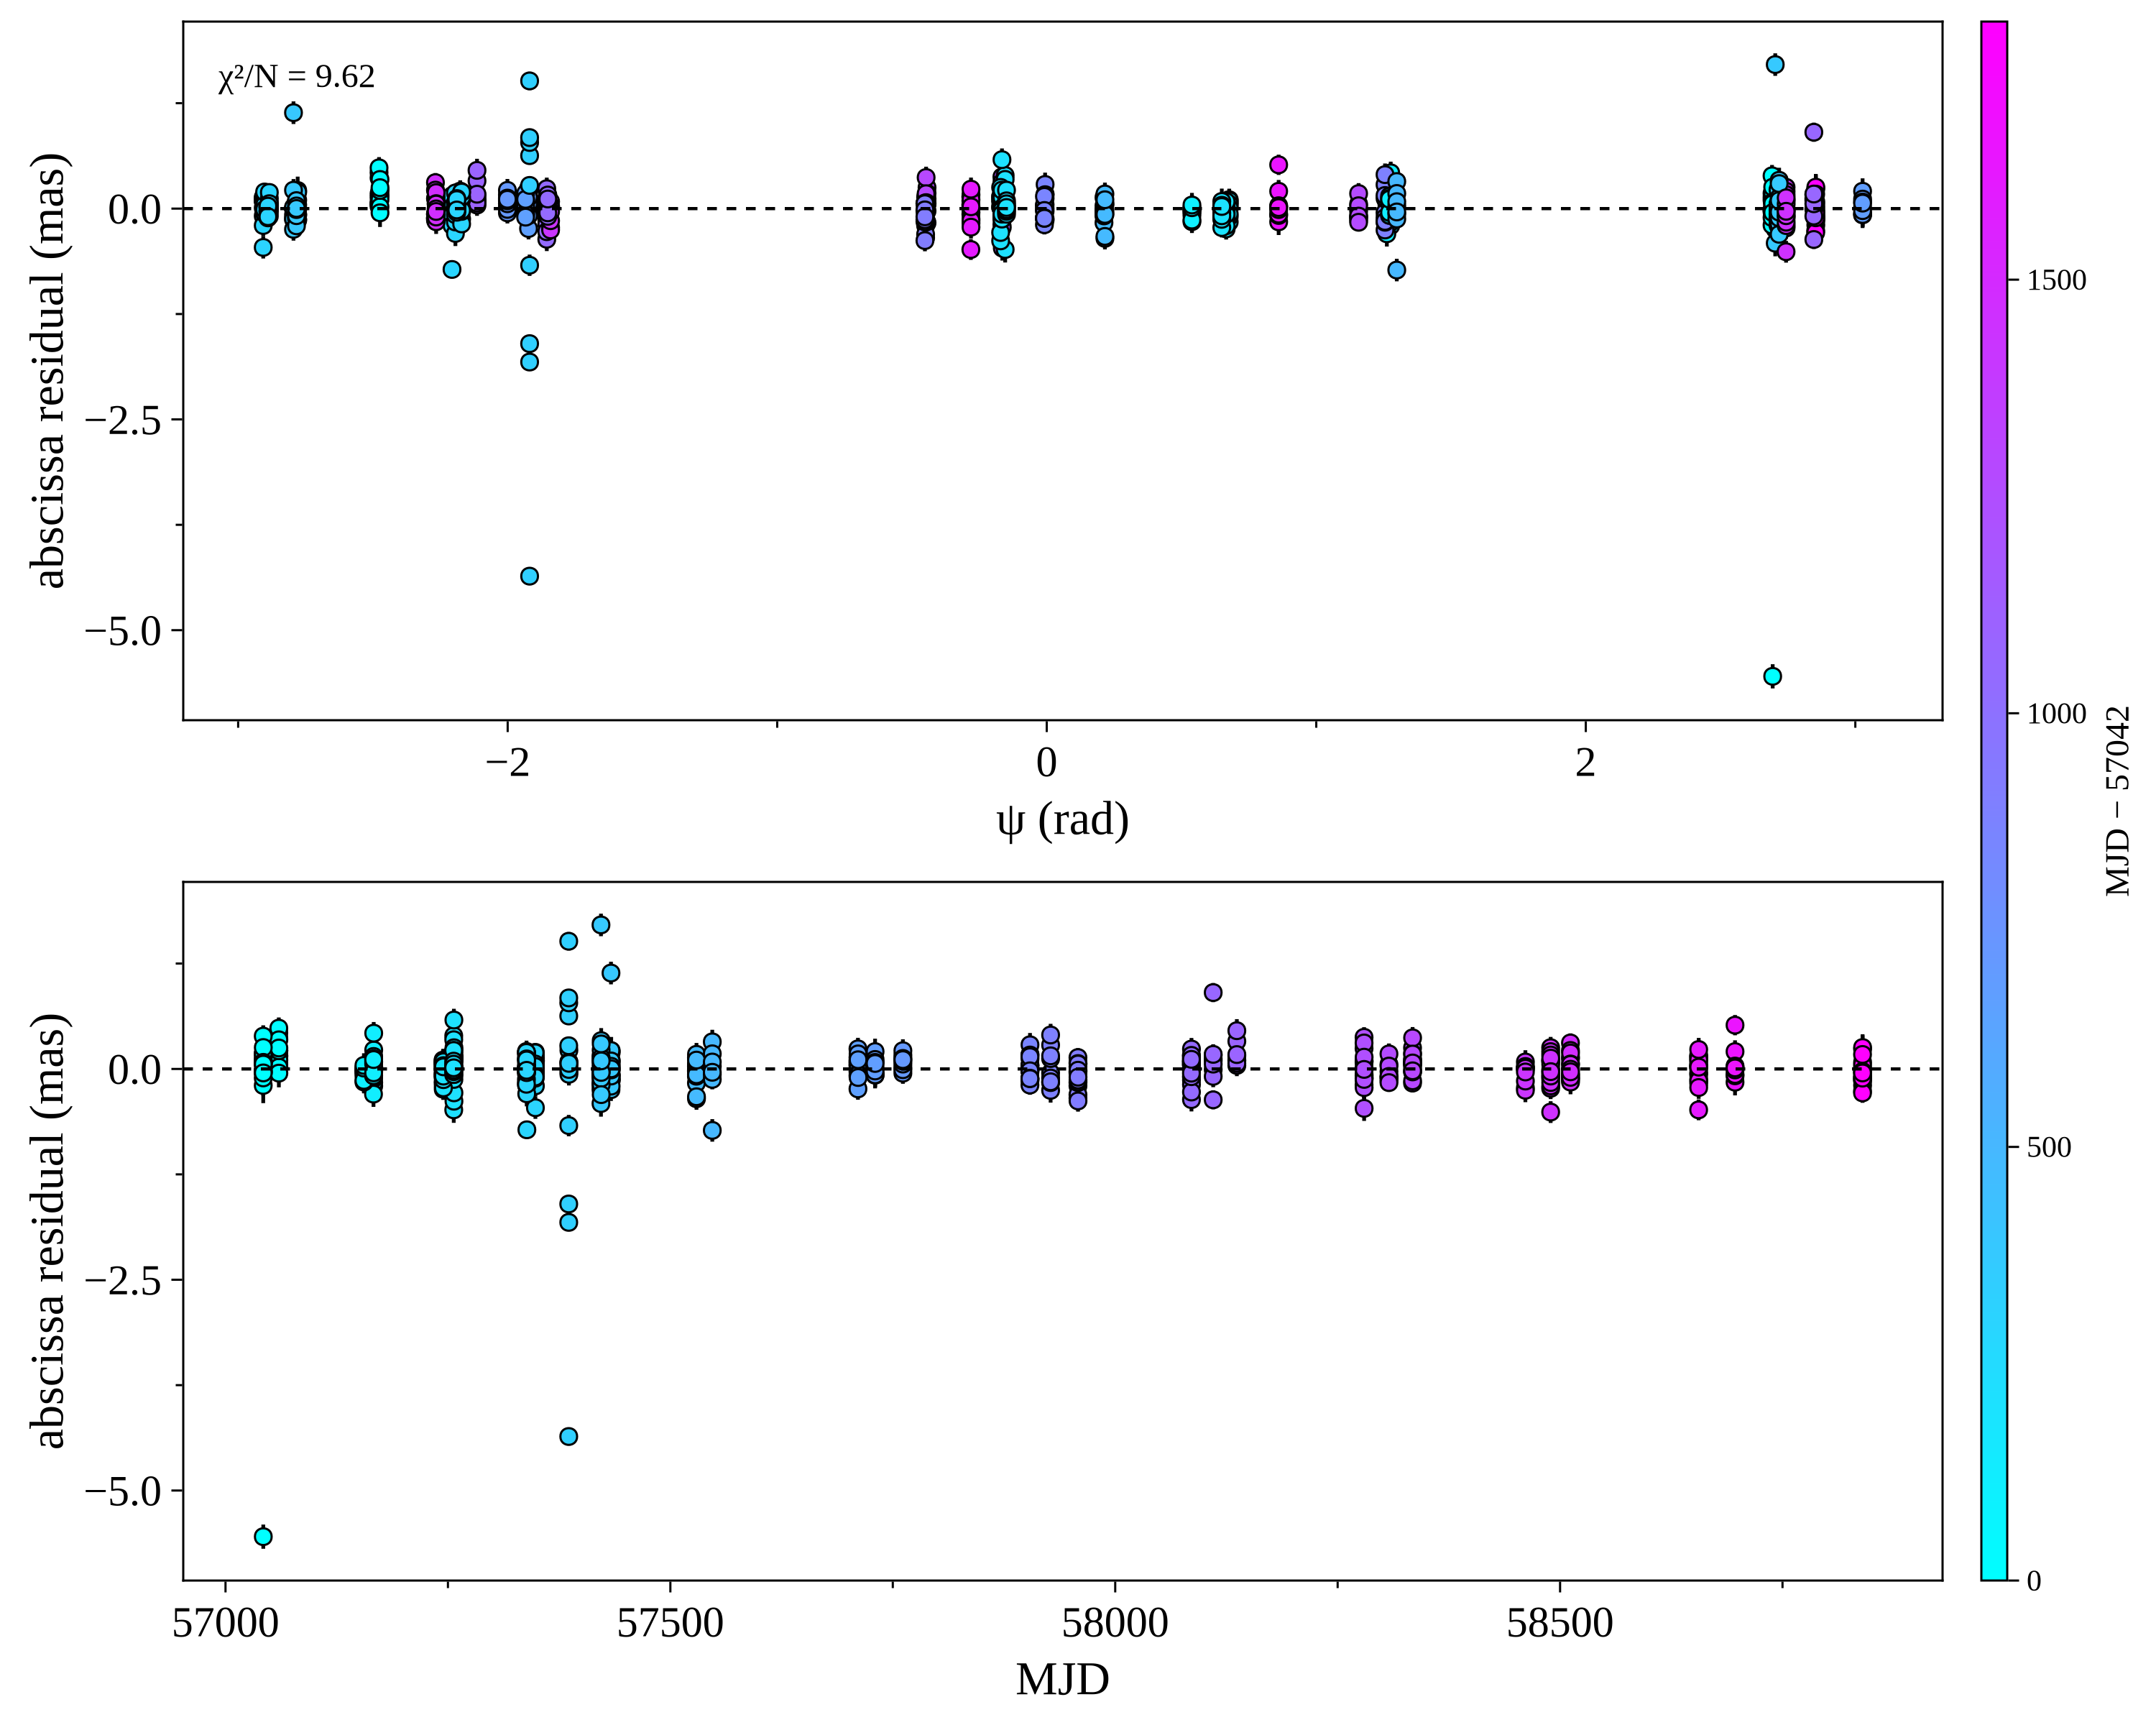

models/RV_phasefold_K1


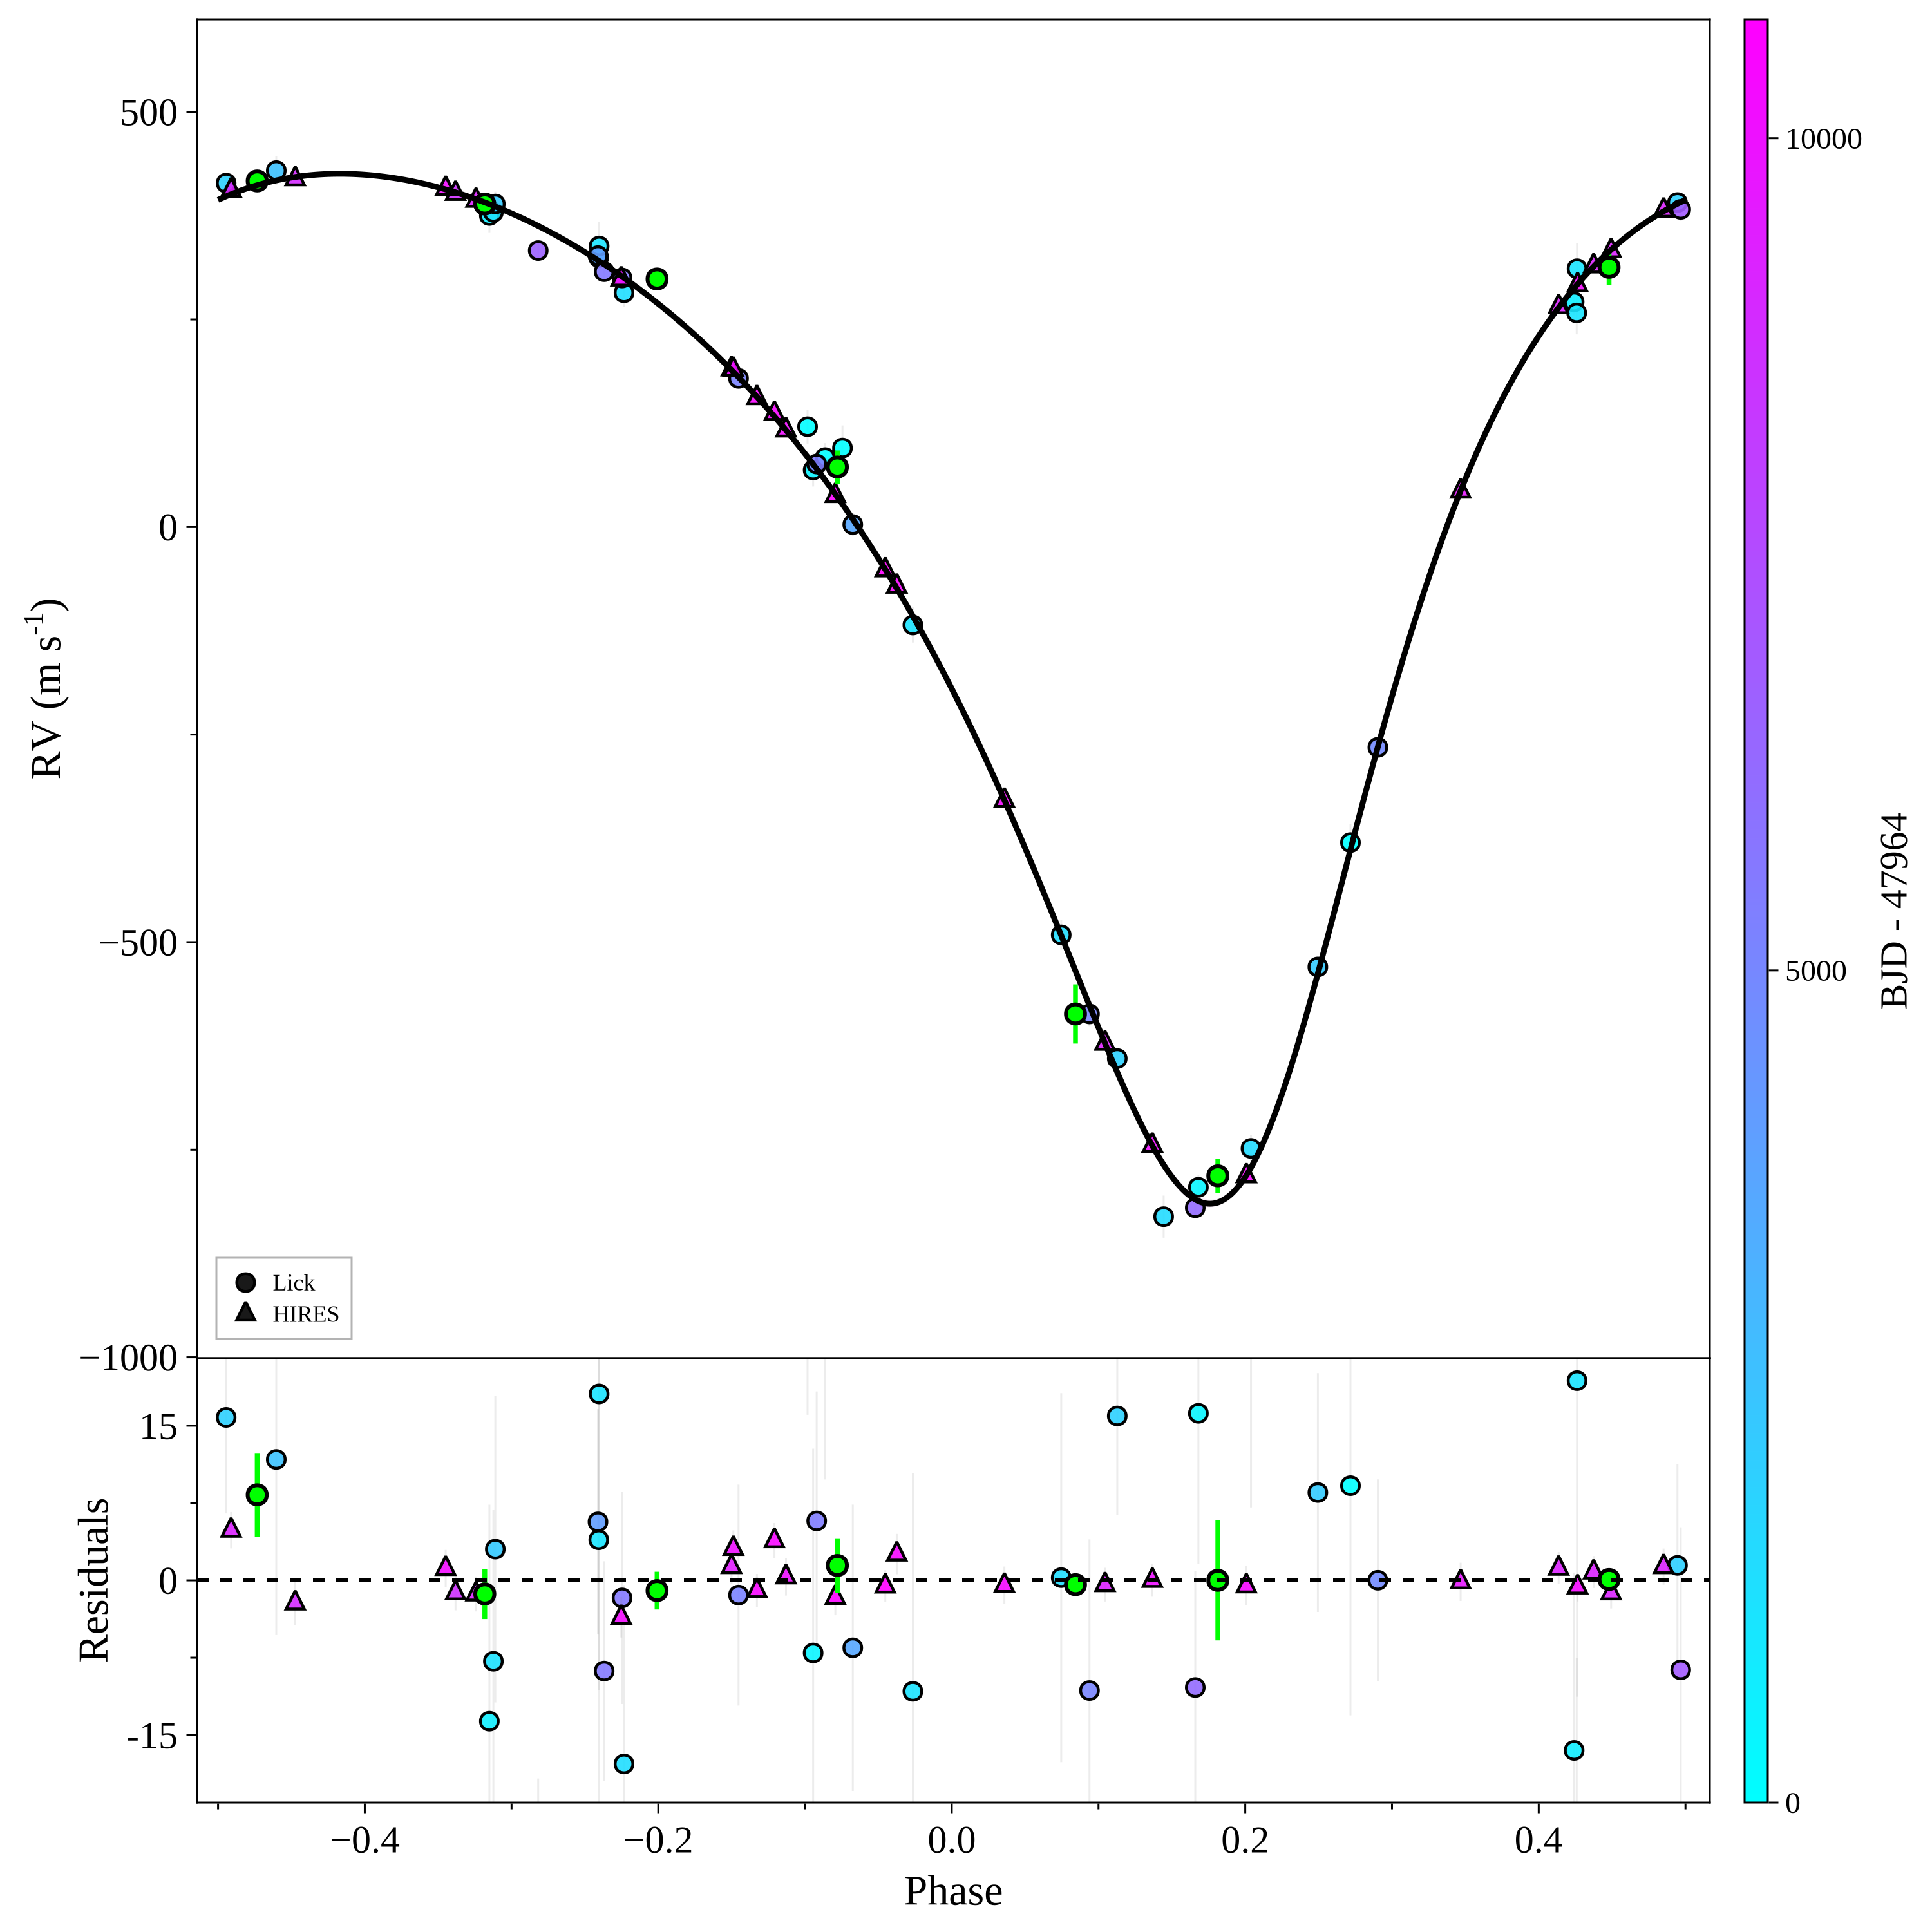

In [16]:
PRIORS_HD = {
    "plx":      {"type": "normal",     "mu": 25.36, "sigma": 0.30},  # mas, Gaia DR3
    "M_pri":    {"type": "fixed",      "value": 0.83},               # M_sun
    "a_k1":     {"type": "loguniform", "lo": 0.30,  "hi": 0.45},     # AU
    "M_sec_k1": {"type": "loguniform", "lo": 0.003, "hi": 0.5},      # M_sun: reaches stellar
    "inc_k1":   {"type": "sine"},
}

res_hd = s.fit_joint(hd.rv, Astrometry(iad=[DR4]), planets=1,
                     priors=PRIORS_HD, M_s=0.83, engine=ptemcee(n_temps=24, n_steps=8000),
                     plots=["epoch_astrometry_orbit", "rv_phasefold", "iad_residuals"],
                     output_dir="tutorial_out/hd114762_joint")
print(res_hd.table())
show(res_hd, "epoch_astrometry_orbit", "RV_phasefold", "iad_residuals")

The velocities alone recover the 1989 orbit: $P = 83.9171 \pm 0.0009$ d, $e = 0.3439 \pm 0.0012$, $M \sin i = 11.1 \pm 0.7\,M_J$.

Gaia sees the star trace an ellipse of semi-major axis 1.9 mas, almost face on: $i = 3.52 \pm 0.02°$, and the companion is $0.199 \pm 0.001\,M_\odot$, or $209\,M_J$. HD 114762 b is a low-mass star, not a brown dwarf. The RV-only $M \sin i$ assumes $M_{\rm sec} \ll M_\star$; at the true mass, $M_{\rm sec} \sin i = 12.8\,M_J$, which gives back the same $K$.

Two things the error bars leave out. $M_{\rm pri}$ is fixed at $0.83\,M_\odot$, so its uncertainty is not in them. And the along-scan residuals sit at $\chi^2/N = 9.6$, driven by a handful of abscissae 1 to 5.5 mas off the model while the rest lie within a few tenths of a mas (the residual panel above). Nereus has no epoch-astrometry jitter term yet, so the likelihood takes the DR4 errors at face value, and the quoted $\pm 0.001\,M_\odot$ and $\pm 0.02°$ are too small.

---
## 5. What a result holds

Every fit returns the same kind of object:

| attribute | what |
|---|---|
| `params` | fitted parameters: median and 68% interval |
| `derived` | physical quantities computed from them per draw (masses, radii, $a$, $T_{\rm eq}$, ...) |
| `table()` | both, in sections |
| `diagnostics` | sampler health: ESS, R-hat, acceptance and swap rates |
| `fit_health` | a structural check of the posterior: convergence, parameters railed against a prior bound, disjoint modes |
| `log_z` | the evidence estimate |
| `figures` | the PNGs Nereus wrote, by name |

On disk, `output_dir` holds the chains (`chains.nc`), `summary.json` and the tables in
CSV, ECSV, JSON and LaTeX.

Check `fit_health` before quoting a number. It fails a posterior that has not
converged, that piles up against a prior bound, or whose chains disagree on where the
mode is.

In [17]:
fits = {"1 NGTS-6 RV": res_rv, "2 NGTS-6 RV+transit": res_rvtr,
        "3 Gaia-4 astrometry": res_g4, "4a Gaia-4 RV+astrometry": res_g4j,
        "4b HD 114762 RV": res_hd_rv, "4b HD 114762 RV+astrometry": res_hd}
for name, res in fits.items():
    print(f"{name:28} {res.fit_health['overall']}")

print()
print(res_g4j.diagnostics)
sorted(os.listdir("tutorial_out/gaia4_joint"))

1 NGTS-6 RV                  ok
2 NGTS-6 RV+transit          ok
3 Gaia-4 astrometry          ok
4a Gaia-4 RV+astrometry      ok
4b HD 114762 RV              ok
4b HD 114762 RV+astrometry   ok

sampler
  log Z             541.00
  likelihood evals  28,802,400
  elapsed           139 s

within-rung acceptance   (beta=1 is the posterior; want ~0.2-0.5)
  cold (beta=1)     0.284
  hottest           0.163
  min / mean        0.124 / 0.164

swap acceptance between adjacent rungs   (min < 0.01 => ladder decoupled)
  min               0.283   at rung pair 0-1
  mean              0.545
  ladder            0.28 0.29 0.32 0.36 0.39 0.41 0.44 0.45 0.47 0.47 0.35 0.42 0.64 0.70 0.71 0.72 0.73 0.73 0.73 0.73 0.74 0.74 0.74

temperatures        24 rungs, beta 1.00e-04 .. 1.00

convergence   (100 chains x 6000 kept iterations)
               ess_bulk  ess_tail   r_hat
  M_sec_k1       115486    150930  1.0009
  Mo_k1          118449    141756  1.0009
  Omega_k1       109555    155981  1.0008
  a_k1   

['chains.nc', 'plots', 'ppc.json', 'ppc.png', 'summary.json', 'tables']

**Where to go next**

- More planets: `planets=2` adds a second Keplerian (`P_k2`, `K_k2`, ...).
- Other samplers: `engines.Nested` (nested sampling, aimed at the evidence) and
  `engines.NUTS` (Hamiltonian Monte Carlo) take the same `engine=` slot.
- Other astrometry: Hipparcos intermediate data (a `{"catalogue": "hipparcos", "hip":
  ...}` entry in `iad=`, next to the Gaia one), Hipparcos–Gaia proper-motion anomalies
  (`Astrometry(hgca=...)`) and relative astrometry from imaging
  (`Astrometry(relast=...)`) combine with velocities the same way as §4.
- The [`astronereus` README](https://github.com/jvines/nereus-py) documents every
  option, and Nereus.jl's
  [`docs/JOB_CONFIG.md`](https://github.com/jvines/Nereus.jl/blob/main/docs/JOB_CONFIG.md)
  documents the job config of §2.

In [18]:
s.stop()